# Compute Valence and Arousal Index 
- Original Tool from SIBling: https://aclanthology.org/2024.acl-long.76/
- **Author:** Naomi Baes

## Load Input Data to Inspect

In [2]:
pwd

'/home/ec2-user/SageMaker/ADHD_conceptual_change'

In [3]:
import os
import pandas as pd

# Set corpus to the folder of files you want to use
df_corpus = pd.read_csv('output/ADHD_US_newsstream_normalized-ADHD_sentences_cleaned.csv', sep=',')
df_warriner_rat = pd.read_csv('/home/ec2-user/SageMaker/resources/warriner_rat.csv')

# print descriptive information
print("Loaded:", df_corpus.shape, "news articles.")
print("Loaded:", df_warriner_rat.shape, "static lemma ratings.")
df_corpus.head()
#df_warriner_rat.head()

# Number of examples to show
N = 5

# Get top/bottom N by word count
longest = df_corpus.nlargest(N, 'sentence_word_len')
shortest = df_corpus.nsmallest(N, 'sentence_word_len')

# Function to pretty‐print a block
def print_block(title, subset):
    print(f"\n▶ {title} (showing {len(subset)} rows):\n")
    for idx, row in subset.iterrows():
        print(
            f"- [{row['year']} | {row['pub_province']}] "
            f"({row['sentence_word_len']} words) → {row['raw_sent']}"
        )
    print()

# Print them
print_block(f"Top {N} longest sentences", longest)
print_block(f"Top {N} shortest sentences", shortest)

Loaded: (103598, 12) news articles.
Loaded: (13915, 65) static lemma ratings.

▶ Top 5 longest sentences (showing 5 rows):

- [2009 | NY] (1628 words) → 16.5 Secondary Research 194   16.6 Primary Research 195   16.7 Models 195   16.8 Forecasts 195   16.8.1 Epidemiology-based Forecasting 195   16.9 Expert Panel Validation 197   16.10 Contact Us 198   16.11 Disclaimer 198   1.1 List of Tables   Table 1: CNS Therapeutics Market, Global, Revenues ($m), 2000-2008 24   Table 2: CNS Therapeutics Market, Global, Revenue Forecasts ($m), 2008-2015 24   Table 3: CNS Therapeutics Market, Global, Revenue Segmentation ($m), 2000-2008 25   Table 4: CNS Therapeutics Market, Global, Revenue Segmentation ($m), 2008-2015 26   Table 5: CNS Therapeutics Market, Global, Historical Figures for Average Cost of Therapy ($), 2000-2008 27   Table 6: CNS Therapeutics Market, Global, Forecasts for Average Cost of Therapy ($),    2008-2015 27   Table 7: CNS Therapeutics Market, Global, Historical Figures for Volume

In [22]:
#!pip install spacy
#!pip install ipywidgets
#!jupyter nbextension enable --py widgetsnbextension

## Preprocessing Data

### OPTION 1: Lemmatize sentences containing target term using **en_core_web_sm**

**Option:** Use **en_core_web_sm** to lemmatize sentences containing the target term.

- **Lemmatization** converts words to their base (dictionary) form, removing morphological variations (e.g., _running_ → _run_, _ran_ → _run_).  
- **Model choice**:  
  - **`en_core_web_sm`** is a lightweight, rule-based pipeline that relies on lookup tables and morphological rules for lemmatization.  
  - It does **not** include contextualized embeddings, so lemmatization is guided primarily by part-of-speech tags and built-in word-to-lemma mappings.  

---

#### Pipeline components

1. **Tokenizer**  
   Splits text into words, punctuation, and spaces.  
2. **Tagger**  
   Assigns part-of-speech tags (e.g., **VERB**, **NOUN**).  
3. **Parser**  
   Analyzes syntactic structure (dependency parse).  
4. **Lemmatizer**  
   Applies lookup tables and morphological rules, using the POS tags to select the correct lemma.  

---

#### Pros & Cons

| Pros                                      | Cons                                                              |
|-------------------------------------------|-------------------------------------------------------------------|
| Very fast and efficient on CPU            | Less accurate for ambiguous words                                 |
| Minimal dependencies and small model size | Rule-based errors on irregular forms may persist                  |

---

#### Installation & Usage

```bash
python -m spacy download en_core_web_sm


This script processes TSV files containing sentences containing target from news articles by:
1. Lemmatizing each sentence while removing stop words, punctuation, and whitespace.
This preprocessing prepares the corpus for downstream tasks like collocate extraction and diachronic semantic analysis.

In [23]:
%run 1_step1_lemmatize_sentences_cpu-parallel.py # OPTION 1 (en_core_web_sm)

[Info] Loading spaCy model: /home/ec2-user/SageMaker/models/en_core_web_sm-3.7.1 (n_process=7) …


/home/ec2-user/SageMaker/.conda/envs/my_py/lib/python3.12/site-packages/spacy/util.py:922: UserWarning: [W095] Model 'en_core_web_sm' (3.7.1) was trained with spaCy v3.7.2 and may not be 100% compatible with the current version (3.8.7). If you see errors or degraded performance, download a newer compatible model or retrain your custom model with the current spaCy version. For more details and available updates, run: python -m spacy validate
  warnings.warn(warn_msg)


[Info] Components active: ['tok2vec', 'tagger', 'attribute_ruler', 'lemmatizer']


Chunks: 0chunk [00:00, ?chunk/s]

[✓] Chunk 1 saved → 5000 rows | Total: 5000
[✓] Chunk 2 saved → 5000 rows | Total: 10000
[✓] Chunk 3 saved → 5000 rows | Total: 15000
[✓] Chunk 4 saved → 5000 rows | Total: 20000
[✓] Chunk 5 saved → 5000 rows | Total: 25000
[✓] Chunk 6 saved → 5000 rows | Total: 30000
[✓] Chunk 7 saved → 5000 rows | Total: 35000
[✓] Chunk 8 saved → 5000 rows | Total: 40000
[✓] Chunk 9 saved → 5000 rows | Total: 45000
[✓] Chunk 10 saved → 5000 rows | Total: 50000
[✓] Chunk 11 saved → 5000 rows | Total: 55000
[✓] Chunk 12 saved → 5000 rows | Total: 60000
[✓] Chunk 13 saved → 5000 rows | Total: 65000
[✓] Chunk 14 saved → 5000 rows | Total: 70000
[✓] Chunk 15 saved → 5000 rows | Total: 75000
[✓] Chunk 16 saved → 5000 rows | Total: 80000
[✓] Chunk 17 saved → 5000 rows | Total: 85000
[✓] Chunk 18 saved → 5000 rows | Total: 90000
[✓] Chunk 19 saved → 5000 rows | Total: 95000
[✓] Chunk 20 saved → 5000 rows | Total: 100000
[✓] Chunk 21 saved → 3598 rows | Total: 103598

[✔] Finished lemmatizing 103598 sentences

In [24]:
# Set corpus to the folder of files you want to use
df_corpus = pd.read_csv('output/ADHD_US_newsstream_normalized-ADHD_sentences_cleaned_lemmatized.csv', sep=',')

# print descriptive information
print("Loaded:", df_corpus.shape, "news articles.")
df_corpus.head()

Loaded: (103598, 13) news articles.


id                                                                                                                                                             title  \
0  1834303976                                                                                                                                    FRUIT NECTARS NEED ADDED SUGAR   
1   277858616                                                                                                                 HYPERACTIVE KIDS' PARENTS GET AN ANSWER - AT LAST   
2   281206290  Hyperactivity Study Yields Clues to Cause, Therapy Psychiatry: Brain abnormality associated with the condition is identified. Up to 5% of children are affected.   
3   281053519                                                                                                                                A NEW WAY TO HELP THOSE HYPER KIDS   
4   281053519                                                                                                                                A NEW WAY TO HELP THOSE HYPER KIDS   

                                     publisher source_type pub_province  year  \
0  Philadelphia Media Network (Newspapers) LLC  Newspapers           PA  1989   
1              Tribune Publishing Company, LLC  Newspapers           IL  1990   
2         Los Angeles Times Communications LLC  Newspapers           CA  1990   
3         Los Angeles Times Communications LLC  Newspapers           CA  1990   
4         Los Angeles Times Communications LLC  Newspapers           CA  1990   

                                                                                                                                                                                                                                            raw_sent  \
0               If by 'hyperactive children and adults' this reader means people who have the disorder that we call 'ADHD,' then caffeine has actually been considered the treatment for this disorder rather than something that should be avoided.   
1                                                                                                                             Two to 4 percent of all school-age children are abnormally hyperactive (the condition is now known medically as ADHD).   
2                                                                                                Hyperactivity, which is now formally called ADHD, is the most common psychiatric disorder of childhood, afflicting from 2% to 5% of all youngsters.   
3                                                                                                                                                      The condition has been called many things, but the proper medical term today is ADHD or ADHD.   
4  Treatment in recent years has depended greatly on the drug Ritalin (methylphenidate), a powerful stimulant that in some ADHD sufferers paradoxically has a calming effect, helping the children follow through on tasks and respond to direction.   

                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                

This script processes lemmatized sentence-level .tsv files to extract and count co-occurrences of a target term (5-word context window) across time. The target term is inferred from the filename (e.g., "trauma" from trauma_articles_lemmatized.tsv). For each sentence, the script identifies up to five words before and after each occurrence of the target term, then aggregates these by year. The output consists of per-year CSV files listing co-occurrences and their frequency, enabling analysis of shifting lexical contexts over time.

In [25]:
%run 1_step2_get_cooccurrences.py

✔ Written: output/cooccurrences_by_year/ADHD_US_newsstream_normalized-ADHD_sentences_cleaned_lemmatized_1987_cooccurrences.csv
✔ Written: output/cooccurrences_by_year/ADHD_US_newsstream_normalized-ADHD_sentences_cleaned_lemmatized_1988_cooccurrences.csv
✔ Written: output/cooccurrences_by_year/ADHD_US_newsstream_normalized-ADHD_sentences_cleaned_lemmatized_1989_cooccurrences.csv
✔ Written: output/cooccurrences_by_year/ADHD_US_newsstream_normalized-ADHD_sentences_cleaned_lemmatized_1990_cooccurrences.csv
✔ Written: output/cooccurrences_by_year/ADHD_US_newsstream_normalized-ADHD_sentences_cleaned_lemmatized_1991_cooccurrences.csv
✔ Written: output/cooccurrences_by_year/ADHD_US_newsstream_normalized-ADHD_sentences_cleaned_lemmatized_1992_cooccurrences.csv
✔ Written: output/cooccurrences_by_year/ADHD_US_newsstream_normalized-ADHD_sentences_cleaned_lemmatized_1993_cooccurrences.csv
✔ Written: output/cooccurrences_by_year/ADHD_US_newsstream_normalized-ADHD_sentences_cleaned_lemmatized_1994_co

## Annual Valence Index
- **Measure**: Annual Count-Weighted Average Valence over Co-occurrences of Target within 5-Word Context Window

**Step-by-step**:
1. **Load valence ratings**: Load a dictionary (from Warriner et al.) where each word has a valence score from 1 (very negative) to 9 (very positive).
2. **Go through each Co-occurrence file**: Read files like trauma_2005_cooccurence.csv, which contain words that appeared near the target (like "trauma") and how often each word occurred that year.
3. **Match words to valence scores**: Match the cooccurences to their valence scores from the dictionary.
4. **Compute average valence score**: Calculate a weighted average valence score, where more frequent words have more influence.
5. **Compute standard error**: Calculate how much variation there is in those valence scores (i.e., how consistent the emotional tone is).
6. **Normalize**: Convert scores to a 0–1 scale so different targets can be compared more easily.
7. **Save the results**: Write one row per target per year with the valence index and error to a CSV file.

In [21]:
from pathlib import Path
import zipfile

models_dir = Path("/home/ec2-user/SageMaker/models")

zip_path = models_dir / "deberta-v3-base-absa-v1.1.zip"
target_dir = models_dir / "deberta-v3-base-absa-v1.1"

if not zip_path.exists():
    raise FileNotFoundError(f"ZIP not found: {zip_path}")

with zipfile.ZipFile(zip_path, "r") as archive:
    file_names = [
        name for name in archive.namelist()
        if name and not name.endswith("/")
    ]

    top_level_names = {
        Path(name).parts[0]
        for name in file_names
    }

    # Avoid accidentally creating:
    # deberta-v3-base-absa-v1.1/deberta-v3-base-absa-v1.1/
    if top_level_names == {"deberta-v3-base-absa-v1.1"}:
        extraction_location = models_dir
    else:
        target_dir.mkdir(parents=True, exist_ok=True)
        extraction_location = target_dir

    archive.extractall(extraction_location)

print("Extracted model to:", target_dir)

Extracted model to: /home/ec2-user/SageMaker/models/deberta-v3-base-absa-v1.1


In [2]:
#%run 1_step3_compute_valence-index.py
#%run 1_step3_compute_valence-index_sentences.py
%run 1_step3_compute_valence_arousal-index_nrc.py
#%run 1_step3_compute_ABSA_sentiment_by_year_sentences.py

Processing co-occurrence files: 100%|██████████| 43/43 [00:02<00:00, 17.63it/s]



Saved: output/annual_valence_indices_nrc.csv
Saved: output/annual_arousal_indices_nrc.csv

NRC valence coverage summary:
count    43.000000
mean      0.828988
std       0.032370
min       0.750000
25%       0.822955
50%       0.828803
75%       0.831176
max       1.000000
Name: nrc_valence_coverage_proportion, dtype: float64

NRC arousal coverage summary:
count    43.000000
mean      0.828988
std       0.032370
min       0.750000
25%       0.822955
50%       0.828803
75%       0.831176
max       1.000000
Name: nrc_arousal_coverage_proportion, dtype: float64


### PLOT Valence and Arousal Indices - Warriner vs NRC-VAD

Annual Warriner–NRC valence correlation: r = 0.971, p < .001
Annual Warriner–NRC arousal correlation: r = 0.699, p < .001

Warriner annual coverage, 1990–2025:
count    36.000000
mean     46.124027
std       0.912468
min      43.828921
25%      45.677365
50%      46.042748
75%      46.542039
max      49.197248
Name: warriner_coverage_percent, dtype: float64

NRC-VAD annual coverage, 1990–2025:
count    36.000000
mean     82.667921
std       0.805823
min      80.534351
25%      82.439125
50%      82.878396
75%      83.043351
max      84.288991
Name: nrc_coverage_percent, dtype: float64


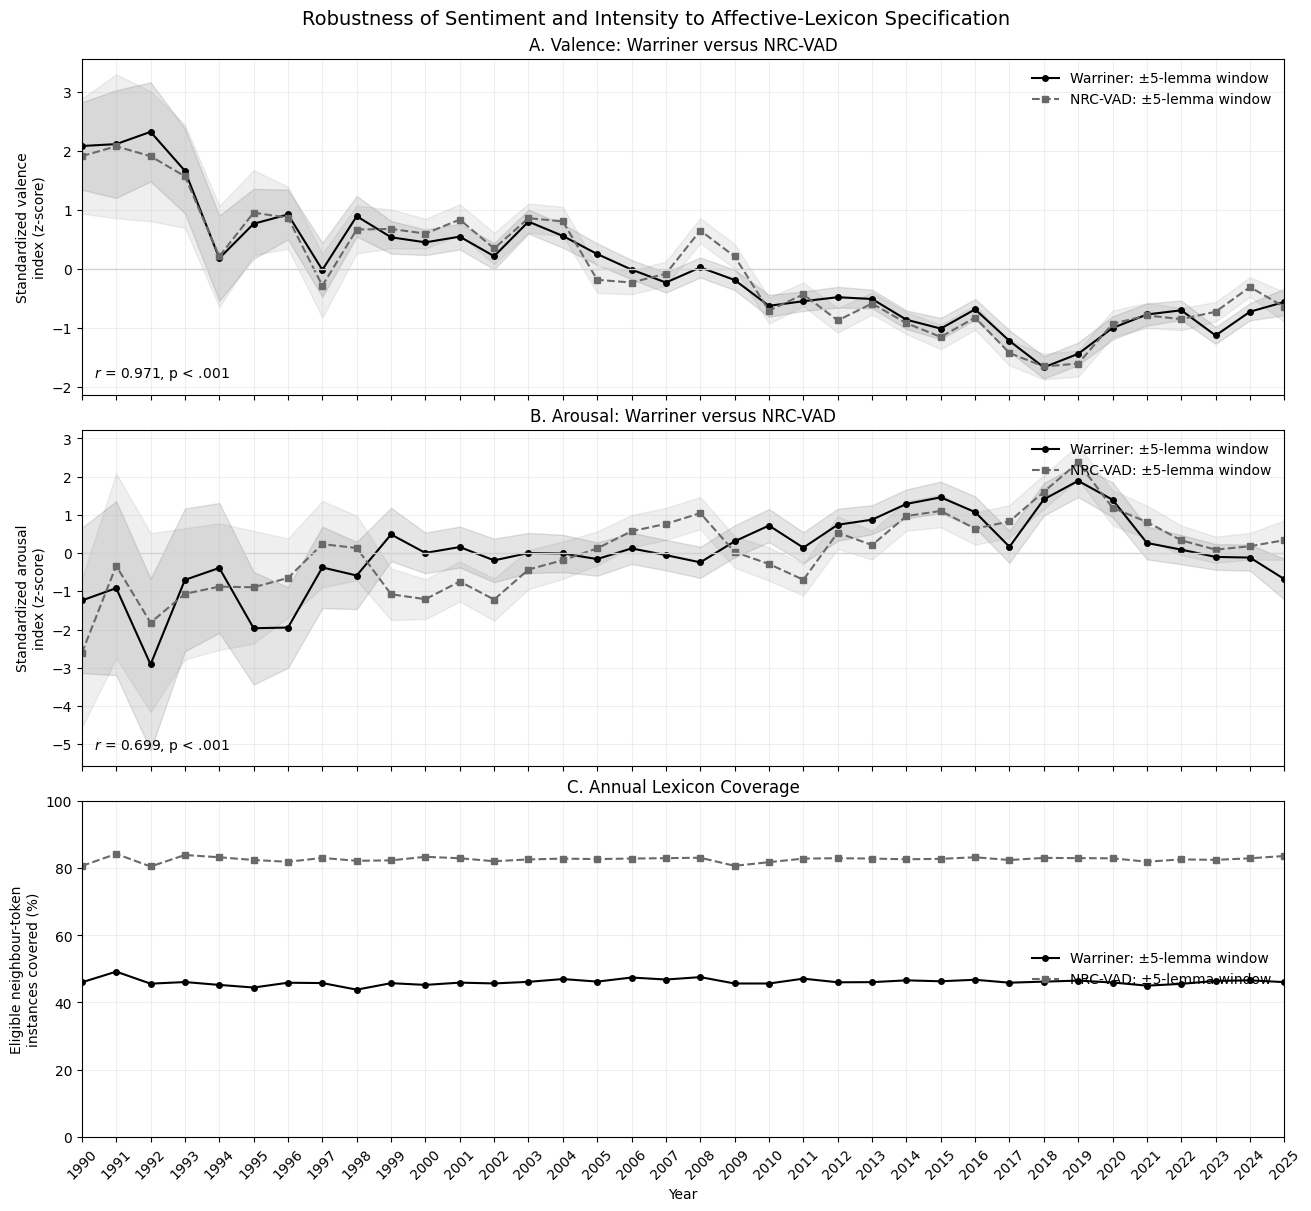

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

# ============================================================
# Load annual Warriner and NRC-VAD results
# ============================================================

warriner_valence = pd.read_csv(
    "output/annual_valence_indices.csv"
)

warriner_arousal = pd.read_csv(
    "output/annual_arousal_indices.csv"
)

nrc_valence = pd.read_csv(
    "output/annual_valence_indices_nrc.csv"
)

nrc_arousal = pd.read_csv(
    "output/annual_arousal_indices_nrc.csv"
)

# ============================================================
# Combine dimensions within each lexicon
# ============================================================

warriner_df = warriner_valence[
    [
        "target",
        "year",
        "avg_valence_index",
        "se_valence_index",
        "warriner_valence_coverage_proportion"
    ]
].merge(
    warriner_arousal[
        [
            "target",
            "year",
            "avg_arousal_index",
            "se_arousal_index"
        ]
    ],
    on=["target", "year"],
    validate="one_to_one"
)

nrc_df = nrc_valence[
    [
        "target",
        "year",
        "avg_valence_index",
        "se_valence_index",
        "nrc_valence_coverage_proportion"
    ]
].merge(
    nrc_arousal[
        [
            "target",
            "year",
            "avg_arousal_index",
            "se_arousal_index"
        ]
    ],
    on=["target", "year"],
    validate="one_to_one"
)

# ============================================================
# Merge lexicons and restrict study period
# ============================================================

plot_df = (
    warriner_df.merge(
        nrc_df,
        on=["target", "year"],
        suffixes=("_warriner", "_nrc"),
        validate="one_to_one"
    )
    .loc[lambda df: df["year"].between(1990, 2025)]
    .sort_values(["target", "year"])
    .reset_index(drop=True)
)

# Keep ADHD only if other targets occur in the files
plot_df = plot_df[
    plot_df["target"].str.upper() == "ADHD"
].copy()

# ============================================================
# Standardize indices separately
# ============================================================

def add_standardized_series(
    dataframe,
    index_column,
    se_column,
    output_prefix
):
    series_sd = dataframe[index_column].std(ddof=1)

    dataframe[f"{output_prefix}_z"] = (
        dataframe[index_column]
        - dataframe[index_column].mean()
    ) / series_sd

    # Convert the native-scale SE to standardized units
    dataframe[f"{output_prefix}_se_z"] = (
        dataframe[se_column] / series_sd
    )


add_standardized_series(
    plot_df,
    "avg_valence_index_warriner",
    "se_valence_index_warriner",
    "warriner_valence"
)

add_standardized_series(
    plot_df,
    "avg_valence_index_nrc",
    "se_valence_index_nrc",
    "nrc_valence"
)

add_standardized_series(
    plot_df,
    "avg_arousal_index_warriner",
    "se_arousal_index_warriner",
    "warriner_arousal"
)

add_standardized_series(
    plot_df,
    "avg_arousal_index_nrc",
    "se_arousal_index_nrc",
    "nrc_arousal"
)

# Convert coverage proportions to percentages
plot_df["warriner_coverage_percent"] = (
    plot_df["warriner_valence_coverage_proportion"] * 100
)

plot_df["nrc_coverage_percent"] = (
    plot_df["nrc_valence_coverage_proportion"] * 100
)

# ============================================================
# Correlations
# ============================================================

valence_r, valence_p = pearsonr(
    plot_df["avg_valence_index_warriner"],
    plot_df["avg_valence_index_nrc"]
)

arousal_r, arousal_p = pearsonr(
    plot_df["avg_arousal_index_warriner"],
    plot_df["avg_arousal_index_nrc"]
)

def format_p(p_value):
    return "p < .001" if p_value < .001 else f"p = {p_value:.3f}"


print(
    "Annual Warriner–NRC valence correlation: "
    f"r = {valence_r:.3f}, {format_p(valence_p)}"
)

print(
    "Annual Warriner–NRC arousal correlation: "
    f"r = {arousal_r:.3f}, {format_p(arousal_p)}"
)

print("\nWarriner annual coverage, 1990–2025:")
print(plot_df["warriner_coverage_percent"].describe())

print("\nNRC-VAD annual coverage, 1990–2025:")
print(plot_df["nrc_coverage_percent"].describe())

# ============================================================
# Three-panel figure
# ============================================================

fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(13, 12),
    sharex=True,
    constrained_layout=True
)

years = plot_df["year"]

# Common styling
warriner_style = {
    "color": "black",
    "linestyle": "-",
    "marker": "o",
    "markersize": 4,
    "linewidth": 1.5,
    "label": "Warriner: ±5-lemma window"
}

nrc_style = {
    "color": "dimgray",
    "linestyle": "--",
    "marker": "s",
    "markersize": 4,
    "linewidth": 1.5,
    "label": "NRC-VAD: ±5-lemma window"
}

# ------------------------------------------------------------
# Panel A: Valence
# ------------------------------------------------------------

axes[0].plot(
    years,
    plot_df["warriner_valence_z"],
    **warriner_style
)

axes[0].fill_between(
    years,
    plot_df["warriner_valence_z"]
    - 1.96 * plot_df["warriner_valence_se_z"],
    plot_df["warriner_valence_z"]
    + 1.96 * plot_df["warriner_valence_se_z"],
    color="black",
    alpha=0.10
)

axes[0].plot(
    years,
    plot_df["nrc_valence_z"],
    **nrc_style
)

axes[0].fill_between(
    years,
    plot_df["nrc_valence_z"]
    - 1.96 * plot_df["nrc_valence_se_z"],
    plot_df["nrc_valence_z"]
    + 1.96 * plot_df["nrc_valence_se_z"],
    color="dimgray",
    alpha=0.10
)

axes[0].axhline(
    0,
    color="lightgray",
    linewidth=1
)

axes[0].set_title(
    "A. Valence: Warriner versus NRC-VAD"
)

axes[0].set_ylabel(
    "Standardized valence\nindex (z-score)"
)

axes[0].text(
    0.01,
    0.05,
    f"$r$ = {valence_r:.3f}, {format_p(valence_p)}",
    transform=axes[0].transAxes
)

axes[0].legend(
    frameon=False,
    loc="upper right"
)

# ------------------------------------------------------------
# Panel B: Arousal
# ------------------------------------------------------------

axes[1].plot(
    years,
    plot_df["warriner_arousal_z"],
    **warriner_style
)

axes[1].fill_between(
    years,
    plot_df["warriner_arousal_z"]
    - 1.96 * plot_df["warriner_arousal_se_z"],
    plot_df["warriner_arousal_z"]
    + 1.96 * plot_df["warriner_arousal_se_z"],
    color="black",
    alpha=0.10
)

axes[1].plot(
    years,
    plot_df["nrc_arousal_z"],
    **nrc_style
)

axes[1].fill_between(
    years,
    plot_df["nrc_arousal_z"]
    - 1.96 * plot_df["nrc_arousal_se_z"],
    plot_df["nrc_arousal_z"]
    + 1.96 * plot_df["nrc_arousal_se_z"],
    color="dimgray",
    alpha=0.10
)

axes[1].axhline(
    0,
    color="lightgray",
    linewidth=1
)

axes[1].set_title(
    "B. Arousal: Warriner versus NRC-VAD"
)

axes[1].set_ylabel(
    "Standardized arousal\nindex (z-score)"
)

axes[1].text(
    0.01,
    0.05,
    f"$r$ = {arousal_r:.3f}, {format_p(arousal_p)}",
    transform=axes[1].transAxes
)

axes[1].legend(
    frameon=False,
    loc="upper right"
)

# ------------------------------------------------------------
# Panel C: Coverage
# ------------------------------------------------------------

axes[2].plot(
    years,
    plot_df["warriner_coverage_percent"],
    **warriner_style
)

axes[2].plot(
    years,
    plot_df["nrc_coverage_percent"],
    **nrc_style
)

axes[2].set_title(
    "C. Annual Lexicon Coverage"
)

axes[2].set_ylabel(
    "Eligible neighbour-token\ninstances covered (%)"
)

axes[2].set_ylim(0, 100)

axes[2].set_xlabel("Year")

axes[2].legend(
    frameon=False,
    loc="center right"
)

# ------------------------------------------------------------
# Shared formatting
# ------------------------------------------------------------

for axis in axes:
    axis.grid(True, alpha=0.20)
    axis.set_xlim(years.min(), years.max())

axes[2].set_xticks(years)
axes[2].tick_params(
    axis="x",
    rotation=45
)

fig.suptitle(
    "Robustness of Sentiment and Intensity "
    "to Affective-Lexicon Specification",
    fontsize=14
)

plt.savefig(
    "output/annual_warriner_vs_nrc_three_panel.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [10]:
import os
import numpy as np
import pandas as pd
import statsmodels.api as sm

from scipy.stats import pearsonr
from statsmodels.stats.anova import anova_lm


# ============================================================
# File paths
# ============================================================

NRC_VALENCE_FILE = "output/annual_valence_indices_nrc.csv"
NRC_AROUSAL_FILE = "output/annual_arousal_indices_nrc.csv"

WARRINER_VALENCE_FILE = "output/annual_valence_indices.csv"
WARRINER_AROUSAL_FILE = "output/annual_arousal_indices.csv"

OUTPUT_FILE = "output/nrc_vad_model_results.txt"


# ============================================================
# Output helper
# ============================================================

output_lines = []


def report(text=""):
    text = str(text)
    print(text)
    output_lines.append(text)


def format_p(p_value):
    if p_value < .001:
        return "p < .001"
    return f"p = {p_value:.3f}"


# ============================================================
# Load and validate annual results
# ============================================================

def load_annual_results(filename, required_index_column):
    df = pd.read_csv(filename)

    required_columns = {
        "target",
        "year",
        required_index_column
    }

    if not required_columns.issubset(df.columns):
        raise KeyError(
            f"{filename} must contain: "
            f"{sorted(required_columns)}"
        )

    df = df[
        df["year"].between(1990, 2025)
    ].copy()

    df = df[
        df["target"].astype(str).str.upper() == "ADHD"
    ].copy()

    df = (
        df
        .sort_values("year")
        .reset_index(drop=True)
    )

    if df["year"].duplicated().any():
        duplicate_years = df.loc[
            df["year"].duplicated(),
            "year"
        ].tolist()

        raise ValueError(
            f"Duplicate years found in {filename}: "
            f"{duplicate_years}"
        )

    expected_years = set(range(1990, 2026))
    observed_years = set(df["year"])

    if observed_years != expected_years:
        missing_years = sorted(
            expected_years - observed_years
        )
        unexpected_years = sorted(
            observed_years - expected_years
        )

        raise ValueError(
            f"Year mismatch in {filename}. "
            f"Missing: {missing_years}; "
            f"unexpected: {unexpected_years}"
        )

    if len(df) != 36:
        raise ValueError(
            f"Expected 36 annual observations in {filename}, "
            f"but found {len(df)}."
        )

    return df


nrc_valence = load_annual_results(
    NRC_VALENCE_FILE,
    "avg_valence_index"
)

nrc_arousal = load_annual_results(
    NRC_AROUSAL_FILE,
    "avg_arousal_index"
)

warriner_valence = load_annual_results(
    WARRINER_VALENCE_FILE,
    "avg_valence_index"
)

warriner_arousal = load_annual_results(
    WARRINER_AROUSAL_FILE,
    "avg_arousal_index"
)


# ============================================================
# Warriner–NRC correlations
# ============================================================

valence_comparison = warriner_valence[
    ["year", "avg_valence_index"]
].merge(
    nrc_valence[
        ["year", "avg_valence_index"]
    ],
    on="year",
    suffixes=("_warriner", "_nrc"),
    validate="one_to_one"
)

arousal_comparison = warriner_arousal[
    ["year", "avg_arousal_index"]
].merge(
    nrc_arousal[
        ["year", "avg_arousal_index"]
    ],
    on="year",
    suffixes=("_warriner", "_nrc"),
    validate="one_to_one"
)

valence_r, valence_p = pearsonr(
    valence_comparison["avg_valence_index_warriner"],
    valence_comparison["avg_valence_index_nrc"]
)

arousal_r, arousal_p = pearsonr(
    arousal_comparison["avg_arousal_index_warriner"],
    arousal_comparison["avg_arousal_index_nrc"]
)

report("WARRINER–NRC ANNUAL CORRELATIONS")
report("================================")

report(
    "Valence: "
    f"r = {valence_r:.3f}, "
    f"{format_p(valence_p)}"
)

report(
    "Arousal: "
    f"r = {arousal_r:.3f}, "
    f"{format_p(arousal_p)}"
)

report()


# ============================================================
# NRC coverage descriptives and temporal trend
# ============================================================

coverage_df = nrc_valence[
    [
        "year",
        "nrc_valence_coverage_proportion"
    ]
].copy()

coverage_df["coverage_percent"] = (
    coverage_df[
        "nrc_valence_coverage_proportion"
    ] * 100
)

coverage_df["year_centered"] = (
    coverage_df["year"]
    - coverage_df["year"].mean()
)

coverage_model = sm.OLS(
    coverage_df["coverage_percent"],
    sm.add_constant(
        coverage_df[["year_centered"]],
        has_constant="add"
    )
).fit()

coverage_slope = coverage_model.params["year_centered"]
coverage_ci = coverage_model.conf_int().loc["year_centered"]
coverage_p = coverage_model.pvalues["year_centered"]

report("NRC-VAD COVERAGE")
report("================")

report(
    "Annual coverage: "
    f"{coverage_df['coverage_percent'].min():.3f}%–"
    f"{coverage_df['coverage_percent'].max():.3f}%; "
    f"M = {coverage_df['coverage_percent'].mean():.3f}%, "
    f"SD = {coverage_df['coverage_percent'].std(ddof=1):.3f}%"
)

report(
    "Temporal trend: "
    f"b = {coverage_slope:.4f} percentage points per year, "
    f"95% CI [{coverage_ci.iloc[0]:.4f}, "
    f"{coverage_ci.iloc[1]:.4f}], "
    f"t({int(coverage_model.df_resid)}) = "
    f"{coverage_model.tvalues['year_centered']:.3f}, "
    f"{format_p(coverage_p)}"
)

report(
    f"Model: F({int(coverage_model.df_model)}, "
    f"{int(coverage_model.df_resid)}) = "
    f"{coverage_model.fvalue:.3f}, "
    f"{format_p(coverage_model.f_pvalue)}, "
    f"adjusted R² = {coverage_model.rsquared_adj:.3f}"
)

report()


# ============================================================
# Linear and quadratic model function
# ============================================================

def analyse_nrc_dimension(df, index_column, label):
    analysis_df = df[
        ["year", index_column]
    ].dropna().copy()

    # Native-scale predictors
    analysis_df["year_centered"] = (
        analysis_df["year"]
        - analysis_df["year"].mean()
    )

    analysis_df["year_centered_squared"] = (
        analysis_df["year_centered"] ** 2
    )

    # Standardized specification used to obtain β coefficients
    analysis_df["year_z"] = (
        analysis_df["year"]
        - analysis_df["year"].mean()
    ) / analysis_df["year"].std(ddof=1)

    analysis_df["year_z_squared"] = (
        analysis_df["year_z"] ** 2
    )

    analysis_df["index_z"] = (
        analysis_df[index_column]
        - analysis_df[index_column].mean()
    ) / analysis_df[index_column].std(ddof=1)

    # --------------------------------------------------------
    # Native-scale models
    # --------------------------------------------------------

    linear_native = sm.OLS(
        analysis_df[index_column],
        sm.add_constant(
            analysis_df[["year_centered"]],
            has_constant="add"
        )
    ).fit()

    quadratic_native = sm.OLS(
        analysis_df[index_column],
        sm.add_constant(
            analysis_df[
                [
                    "year_centered",
                    "year_centered_squared"
                ]
            ],
            has_constant="add"
        )
    ).fit()

    # --------------------------------------------------------
    # Standardized models
    # --------------------------------------------------------

    linear_standardized = sm.OLS(
        analysis_df["index_z"],
        sm.add_constant(
            analysis_df[["year_z"]],
            has_constant="add"
        )
    ).fit()

    quadratic_standardized = sm.OLS(
        analysis_df["index_z"],
        sm.add_constant(
            analysis_df[
                [
                    "year_z",
                    "year_z_squared"
                ]
            ],
            has_constant="add"
        )
    ).fit()

    # Nested-model comparison
    model_comparison = anova_lm(
        linear_native,
        quadratic_native
    )

    delta_f = model_comparison.iloc[1]["F"]
    delta_p = model_comparison.iloc[1]["Pr(>F)"]

    # Native coefficient confidence intervals
    linear_ci = (
        linear_native
        .conf_int()
        .loc["year_centered"]
    )

    quadratic_linear_ci = (
        quadratic_native
        .conf_int()
        .loc["year_centered"]
    )

    quadratic_term_ci = (
        quadratic_native
        .conf_int()
        .loc["year_centered_squared"]
    )

    # Quadratic turning point
    raw_linear_component = (
        quadratic_native.params["year_centered"]
    )

    raw_quadratic_component = (
        quadratic_native.params[
            "year_centered_squared"
        ]
    )

    if raw_quadratic_component != 0:
        turning_point_centered = (
            -raw_linear_component
            / (2 * raw_quadratic_component)
        )

        turning_point_year = (
            analysis_df["year"].mean()
            + turning_point_centered
        )
    else:
        turning_point_year = np.nan

    # Predicted endpoint difference from quadratic model
    prediction_df = pd.DataFrame(
        {
            "year_centered": [
                1990 - analysis_df["year"].mean(),
                2025 - analysis_df["year"].mean()
            ]
        }
    )

    prediction_df["year_centered_squared"] = (
        prediction_df["year_centered"] ** 2
    )

    endpoint_predictions = quadratic_native.predict(
        sm.add_constant(
            prediction_df[
                [
                    "year_centered",
                    "year_centered_squared"
                ]
            ],
            has_constant="add"
        )
    )

    predicted_change = (
        endpoint_predictions.iloc[1]
        - endpoint_predictions.iloc[0]
    )

    # --------------------------------------------------------
    # Print results
    # --------------------------------------------------------

    report(label.upper())
    report("=" * len(label))

    report(
        "Annual NRC index: "
        f"M = {analysis_df[index_column].mean():.4f}, "
        f"SD = {analysis_df[index_column].std(ddof=1):.4f}, "
        f"range = "
        f"{analysis_df[index_column].min():.4f}–"
        f"{analysis_df[index_column].max():.4f}"
    )

    report()
    report("Linear model")

    report(
        f"F({int(linear_native.df_model)}, "
        f"{int(linear_native.df_resid)}) = "
        f"{linear_native.fvalue:.3f}, "
        f"{format_p(linear_native.f_pvalue)}, "
        f"adjusted R² = "
        f"{linear_native.rsquared_adj:.3f}"
    )

    report(
        "Native slope: "
        f"b = "
        f"{linear_native.params['year_centered']:.6f}, "
        f"95% CI [{linear_ci.iloc[0]:.6f}, "
        f"{linear_ci.iloc[1]:.6f}], "
        f"t({int(linear_native.df_resid)}) = "
        f"{linear_native.tvalues['year_centered']:.3f}, "
        f"{format_p(linear_native.pvalues['year_centered'])}"
    )

    report(
        "Standardized coefficient: "
        f"β = "
        f"{linear_standardized.params['year_z']:.3f}, "
        f"{format_p(linear_standardized.pvalues['year_z'])}"
    )

    report(
        f"AIC = {linear_native.aic:.3f}; "
        f"BIC = {linear_native.bic:.3f}"
    )

    report()
    report("Quadratic model")

    report(
        f"F({int(quadratic_native.df_model)}, "
        f"{int(quadratic_native.df_resid)}) = "
        f"{quadratic_native.fvalue:.3f}, "
        f"{format_p(quadratic_native.f_pvalue)}, "
        f"adjusted R² = "
        f"{quadratic_native.rsquared_adj:.3f}"
    )

    report(
        "Linear component, native scale: "
        f"b = {raw_linear_component:.6f}, "
        f"95% CI [{quadratic_linear_ci.iloc[0]:.6f}, "
        f"{quadratic_linear_ci.iloc[1]:.6f}], "
        f"{format_p(quadratic_native.pvalues['year_centered'])}"
    )

    report(
        "Quadratic component, native scale: "
        f"b = {raw_quadratic_component:.8f}, "
        f"95% CI [{quadratic_term_ci.iloc[0]:.8f}, "
        f"{quadratic_term_ci.iloc[1]:.8f}], "
        f"{format_p(
            quadratic_native.pvalues[
                'year_centered_squared'
            ]
        )}"
    )

    report(
        "Standardized polynomial coefficients: "
        f"linear β = "
        f"{quadratic_standardized.params['year_z']:.3f}, "
        f"{format_p(
            quadratic_standardized.pvalues['year_z']
        )}; "
        f"quadratic β = "
        f"{quadratic_standardized.params[
            'year_z_squared'
        ]:.3f}, "
        f"{format_p(
            quadratic_standardized.pvalues[
                'year_z_squared'
            ]
        )}"
    )

    report(
        "Improvement over linear model: "
        f"ΔF(1, {int(quadratic_native.df_resid)}) = "
        f"{delta_f:.3f}, "
        f"{format_p(delta_p)}"
    )

    report(
        f"AIC = {quadratic_native.aic:.3f}; "
        f"BIC = {quadratic_native.bic:.3f}"
    )

    report(
        "Estimated quadratic turning point: "
        f"{turning_point_year:.2f}"
    )

    report(
        "Quadratic-model predicted change, "
        f"1990–2025: {predicted_change:.4f} "
        "NRC units"
    )

    report()
    report("-" * 70)
    report()

    return {
        "linear_native": linear_native,
        "quadratic_native": quadratic_native,
        "linear_standardized": linear_standardized,
        "quadratic_standardized": quadratic_standardized,
        "model_comparison": model_comparison
    }


# ============================================================
# Run NRC Valence and Arousal models
# ============================================================

valence_models = analyse_nrc_dimension(
    nrc_valence,
    "avg_valence_index",
    "NRC-VAD Valence"
)

arousal_models = analyse_nrc_dimension(
    nrc_arousal,
    "avg_arousal_index",
    "NRC-VAD Arousal"
)


# ============================================================
# Save output
# ============================================================

os.makedirs("output", exist_ok=True)

with open(
    OUTPUT_FILE,
    "w",
    encoding="utf-8"
) as output_handle:
    output_handle.write(
        "\n".join(output_lines)
    )

report(f"Saved statistical output to: {OUTPUT_FILE}")

WARRINER–NRC ANNUAL CORRELATIONS
Valence: r = 0.971, p < .001
Arousal: r = 0.699, p < .001

NRC-VAD COVERAGE
Annual coverage: 80.534%–84.289%; M = 82.668%, SD = 0.806%
Temporal trend: b = 0.0121 percentage points per year, 95% CI [-0.0142, 0.0384], t(34) = 0.935, p = 0.356
Model: F(1, 34) = 0.874, p = 0.356, adjusted R² = -0.004

NRC-VAD VALENCE
Annual NRC index: M = 0.0983, SD = 0.0226, range = 0.0612–0.1452

Linear model
F(1, 34) = 89.762, p < .001, adjusted R² = 0.717
Native slope: b = -0.001824, 95% CI [-0.002215, -0.001432], t(34) = -9.474, p < .001
Standardized coefficient: β = -0.852, p < .001
AIC = -214.356; BIC = -211.189

Quadratic model
F(2, 33) = 57.333, p < .001, adjusted R² = 0.763
Linear component, native scale: b = -0.001824, 95% CI [-0.002182, -0.001465], p < .001
Quadratic component, native scale: b = 0.00005223, 95% CI [0.00001360, 0.00009086], p = 0.010
Standardized polynomial coefficients: linear β = -0.852, p < .001; quadratic β = 0.257, p = 0.010
Improvement over

#### ABSA alternative

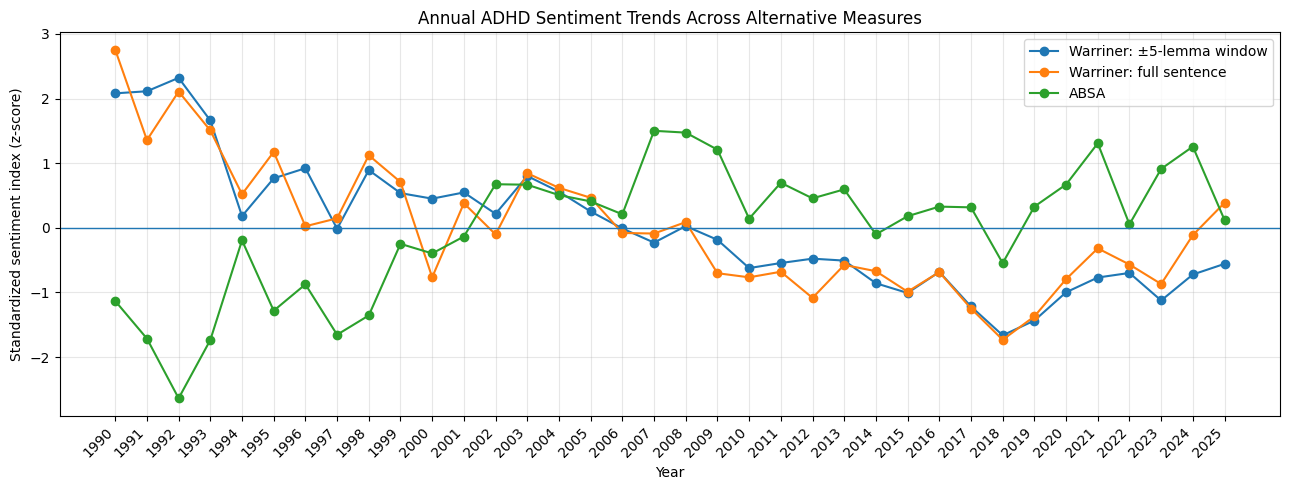

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

# Load
window_df = pd.read_csv("output/annual_valence_indices.csv")
sentence_df = pd.read_csv("output/annual_valence_indices_full_sentence.csv")
absa_df = pd.read_csv("output/annual_ABSA_sentiment_indices.csv")

# Restrict years
window_df = window_df[window_df["year"].between(1990, 2025)].copy()
sentence_df = sentence_df[sentence_df["year"].between(1990, 2025)].copy()
absa_df = absa_df[absa_df["year"].between(1990, 2025)].copy()

# Merge
plot_df = (
    window_df[["year", "avg_valence_index"]]
    .merge(
        sentence_df[["year", "avg_valence_index"]],
        on="year",
        suffixes=("_window5", "_sentence")
    )
    .merge(
        absa_df[["year", "avg_absa_sentiment_index"]],
        on="year"
    )
    .sort_values("year")
)

# Standardize each annual series separately
cols = [
    "avg_valence_index_window5",
    "avg_valence_index_sentence",
    "avg_absa_sentiment_index"
]

for col in cols:
    plot_df[col + "_z"] = (
        plot_df[col] - plot_df[col].mean()
    ) / plot_df[col].std()

# Plot
plt.figure(figsize=(13, 5))

plt.plot(
    plot_df["year"],
    plot_df["avg_valence_index_window5_z"],
    marker="o",
    label="Warriner: ±5-lemma window"
)

plt.plot(
    plot_df["year"],
    plot_df["avg_valence_index_sentence_z"],
    marker="o",
    label="Warriner: full sentence"
)

plt.plot(
    plot_df["year"],
    plot_df["avg_absa_sentiment_index_z"],
    marker="o",
    label="ABSA"
)

plt.axhline(0, linewidth=1)

plt.xticks(
    plot_df["year"],
    rotation=45,
    ha="right"
)

plt.xlabel("Year")
plt.ylabel("Standardized sentiment index (z-score)")
plt.title("Annual ADHD Sentiment Trends Across Alternative Measures")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [5]:
import statsmodels.formula.api as smf
import pandas as pd

absa_test = plot_df[
    ["year", "avg_absa_sentiment_index"]
].copy()

# Center year for numerical stability
absa_test["year_c"] = (
    absa_test["year"] - absa_test["year"].mean()
)

absa_test["year_c2"] = (
    absa_test["year_c"] ** 2
)

# Linear model
linear = smf.ols(
    "avg_absa_sentiment_index ~ year_c",
    data=absa_test
).fit()

# Quadratic model
quadratic = smf.ols(
    "avg_absa_sentiment_index ~ year_c + year_c2",
    data=absa_test
).fit()

print("\nLINEAR MODEL")
print(linear.summary())

print("\nQUADRATIC MODEL")
print(quadratic.summary())

print("\nDoes the quadratic term significantly improve fit?")
print(quadratic.compare_f_test(linear))


LINEAR MODEL
                               OLS Regression Results                               
Dep. Variable:     avg_absa_sentiment_index   R-squared:                       0.450
Model:                                  OLS   Adj. R-squared:                  0.434
Method:                       Least Squares   F-statistic:                     27.85
Date:                      Fri, 07 Aug 2026   Prob (F-statistic):           7.49e-06
Time:                              08:57:51   Log-Likelihood:                 124.64
No. Observations:                        36   AIC:                            -245.3
Df Residuals:                            34   BIC:                            -242.1
Df Model:                                 1                                         
Covariance Type:                  nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------

In [9]:
# ============================================================
# FULL-SENTENCE WARRINER INTENSITY ROBUSTNESS
# ============================================================

import pandas as pd
import statsmodels.formula.api as smf
from scipy.stats import pearsonr

# Load primary ±5 and full-sentence arousal indices
arousal_window = pd.read_csv(
    "output/annual_arousal_indices.csv"
)

arousal_sentence = pd.read_csv(
    "output/annual_arousal_indices_full_sentence.csv"
)

# Restrict to study period
arousal_window = arousal_window[
    arousal_window["year"].between(1990, 2025)
].copy()

arousal_sentence = arousal_sentence[
    arousal_sentence["year"].between(1990, 2025)
].copy()

# Merge
arousal_df = arousal_window[
    ["year", "avg_arousal_index"]
].merge(
    arousal_sentence[
        ["year", "avg_arousal_index"]
    ],
    on="year",
    suffixes=("_window5", "_sentence")
)

# ------------------------------------------------------------
# Linear and quadratic models for FULL-SENTENCE intensity
# ------------------------------------------------------------

d = arousal_df[
    ["year", "avg_arousal_index_sentence"]
].copy()

d["year_c"] = d["year"] - d["year"].mean()
d["year_c2"] = d["year_c"] ** 2

linear = smf.ols(
    "avg_arousal_index_sentence ~ year_c",
    data=d
).fit()

quadratic = smf.ols(
    "avg_arousal_index_sentence ~ year_c + year_c2",
    data=d
).fit()

comp = quadratic.compare_f_test(linear)

print("=" * 75)
print("FULL-SENTENCE WARRINER INTENSITY")
print("=" * 75)

print(
    f"Linear: F({int(linear.df_model)}, {int(linear.df_resid)}) = "
    f"{linear.fvalue:.3f}, "
    f"p = {linear.f_pvalue:.6g}, "
    f"adj. R² = {linear.rsquared_adj:.3f}"
)

print(
    f"  year b = {linear.params['year_c']:.6f}, "
    f"p = {linear.pvalues['year_c']:.6g}"
)

print(
    f"Quadratic: F({int(quadratic.df_model)}, {int(quadratic.df_resid)}) = "
    f"{quadratic.fvalue:.3f}, "
    f"p = {quadratic.f_pvalue:.6g}, "
    f"adj. R² = {quadratic.rsquared_adj:.3f}"
)

print(
    f"  linear component b = {quadratic.params['year_c']:.6f}, "
    f"p = {quadratic.pvalues['year_c']:.6g}"
)

print(
    f"  quadratic component b = {quadratic.params['year_c2']:.8f}, "
    f"p = {quadratic.pvalues['year_c2']:.6g}"
)

print(
    f"Quadratic improvement: F(1, {int(quadratic.df_resid)}) = "
    f"{comp[0]:.3f}, p = {comp[1]:.6g}"
)

# ------------------------------------------------------------
# Correlation: ±5 versus full sentence
# ------------------------------------------------------------

r_int, p_int = pearsonr(
    arousal_df["avg_arousal_index_window5"],
    arousal_df["avg_arousal_index_sentence"]
)

print("\n" + "=" * 75)
print("INTENSITY CORRELATION")
print("=" * 75)

print(
    f"Warriner ±5 vs full sentence: "
    f"r = {r_int:.3f}, p = {p_int:.6g}"
)

FULL-SENTENCE WARRINER INTENSITY
Linear: F(1, 34) = 11.217, p = 0.00199349, adj. R² = 0.226
  year b = 0.000946, p = 0.00199349
Quadratic: F(2, 33) = 21.215, p = 1.19112e-06, adj. R² = 0.536
  linear component b = 0.000946, p = 0.000132326
  quadratic component b = -0.00011482, p = 2.70281e-05
Quadratic improvement: F(1, 33) = 23.719, p = 2.70281e-05

INTENSITY CORRELATION
Warriner ±5 vs full sentence: r = 0.839, p = 1.68706e-10


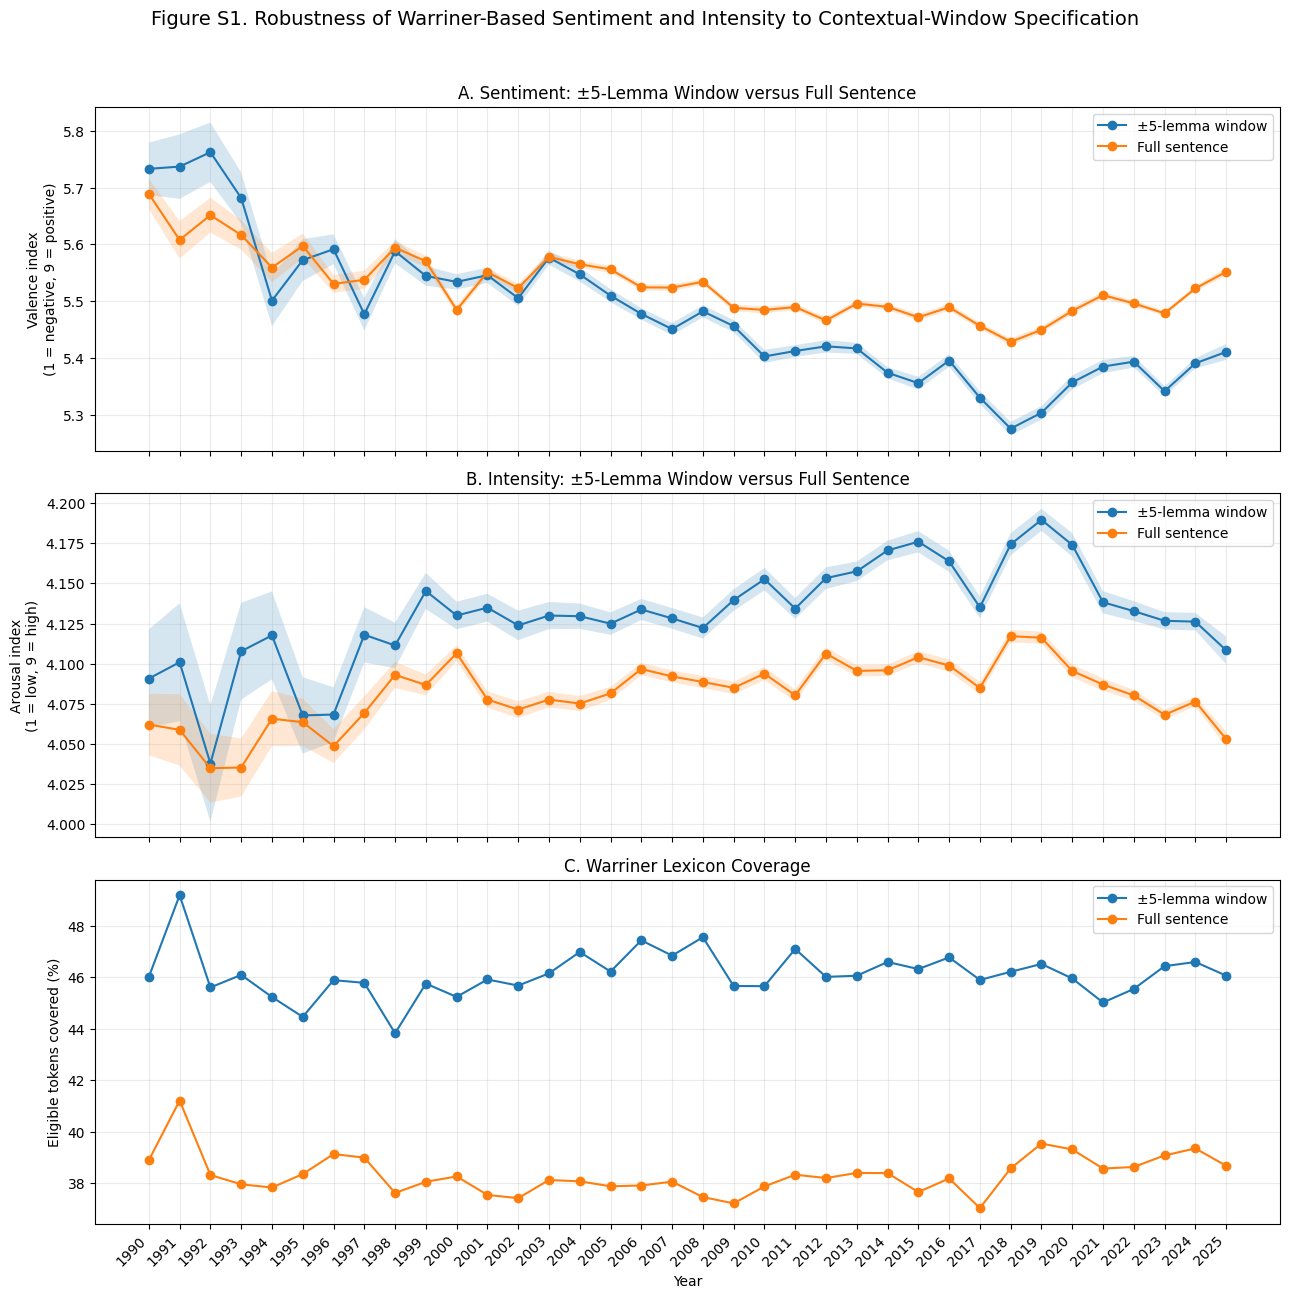

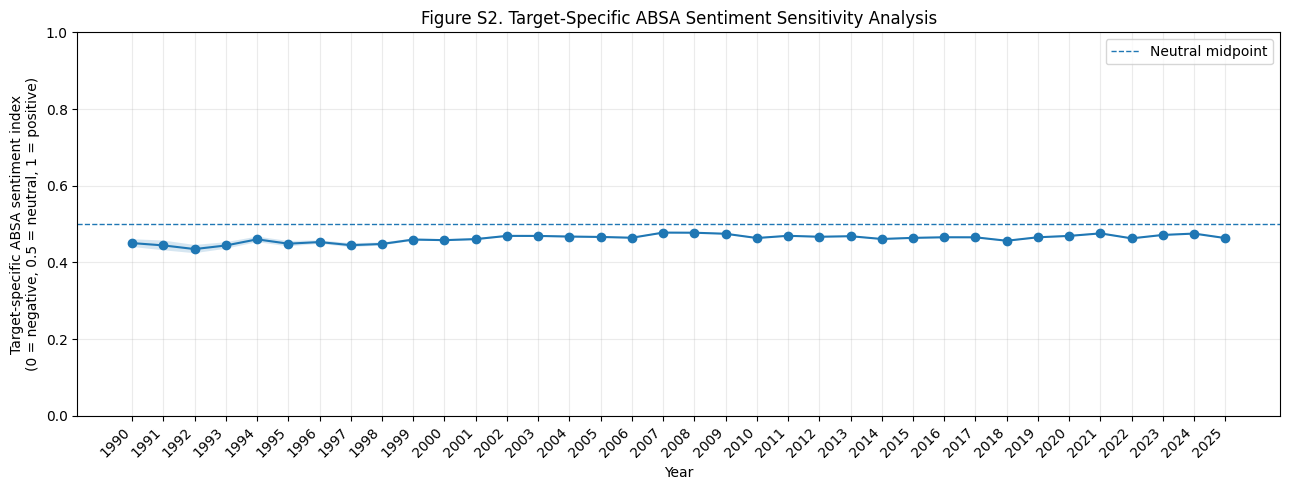

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# LOAD DATA
# ============================================================

# Warriner Sentiment
val_window = pd.read_csv(
    "output/annual_valence_indices.csv"
)

val_sentence = pd.read_csv(
    "output/annual_valence_indices_full_sentence.csv"
)

# Warriner Intensity
aro_window = pd.read_csv(
    "output/annual_arousal_indices.csv"
)

aro_sentence = pd.read_csv(
    "output/annual_arousal_indices_full_sentence.csv"
)

# ABSA Sentiment
absa = pd.read_csv(
    "output/annual_ABSA_sentiment_indices.csv"
)

# Restrict to study years
for df in [
    val_window,
    val_sentence,
    aro_window,
    aro_sentence,
    absa
]:
    df.drop(
        df[~df["year"].between(1990, 2025)].index,
        inplace=True
    )


# ============================================================
# MERGE WARRINER DATA
# ============================================================

val_plot = (
    val_window[
        [
            "year",
            "avg_valence_index",
            "se_valence_index",
            "warriner_valence_coverage_proportion"
        ]
    ]
    .merge(
        val_sentence[
            [
                "year",
                "avg_valence_index",
                "se_valence_index",
                "warriner_valence_coverage_proportion"
            ]
        ],
        on="year",
        suffixes=("_window5", "_sentence")
    )
    .sort_values("year")
)

aro_plot = (
    aro_window[
        [
            "year",
            "avg_arousal_index",
            "se_arousal_index"
        ]
    ]
    .merge(
        aro_sentence[
            [
                "year",
                "avg_arousal_index",
                "se_arousal_index"
            ]
        ],
        on="year",
        suffixes=("_window5", "_sentence")
    )
    .sort_values("year")
)


# ============================================================
# FIGURE S1
# Robustness of Warriner-based Sentiment and Intensity
# to contextual-window specification
# ============================================================

fig, axes = plt.subplots(
    3,
    1,
    figsize=(13, 13),
    sharex=True
)

years = val_plot["year"].to_numpy()


# ------------------------------------------------------------
# PANEL A: SENTIMENT
# ------------------------------------------------------------

ax = axes[0]

ax.plot(
    years,
    val_plot["avg_valence_index_window5"],
    marker="o",
    label="±5-lemma window"
)

ax.fill_between(
    years,
    val_plot["avg_valence_index_window5"]
        - val_plot["se_valence_index_window5"],
    val_plot["avg_valence_index_window5"]
        + val_plot["se_valence_index_window5"],
    alpha=0.18
)

ax.plot(
    years,
    val_plot["avg_valence_index_sentence"],
    marker="o",
    label="Full sentence"
)

ax.fill_between(
    years,
    val_plot["avg_valence_index_sentence"]
        - val_plot["se_valence_index_sentence"],
    val_plot["avg_valence_index_sentence"]
        + val_plot["se_valence_index_sentence"],
    alpha=0.18
)

ax.set_title(
    "A. Sentiment: ±5-Lemma Window versus Full Sentence"
)

ax.set_ylabel(
    "Valence index\n(1 = negative, 9 = positive)"
)

ax.legend()
ax.grid(True, alpha=0.25)


# ------------------------------------------------------------
# PANEL B: INTENSITY
# ------------------------------------------------------------

ax = axes[1]

ax.plot(
    years,
    aro_plot["avg_arousal_index_window5"],
    marker="o",
    label="±5-lemma window"
)

ax.fill_between(
    years,
    aro_plot["avg_arousal_index_window5"]
        - aro_plot["se_arousal_index_window5"],
    aro_plot["avg_arousal_index_window5"]
        + aro_plot["se_arousal_index_window5"],
    alpha=0.18
)

ax.plot(
    years,
    aro_plot["avg_arousal_index_sentence"],
    marker="o",
    label="Full sentence"
)

ax.fill_between(
    years,
    aro_plot["avg_arousal_index_sentence"]
        - aro_plot["se_arousal_index_sentence"],
    aro_plot["avg_arousal_index_sentence"]
        + aro_plot["se_arousal_index_sentence"],
    alpha=0.18
)

ax.set_title(
    "B. Intensity: ±5-Lemma Window versus Full Sentence"
)

ax.set_ylabel(
    "Arousal index\n(1 = low, 9 = high)"
)

ax.legend()
ax.grid(True, alpha=0.25)


# ------------------------------------------------------------
# PANEL C: WARRINER COVERAGE
# ------------------------------------------------------------

ax = axes[2]

coverage_window = (
    val_plot[
        "warriner_valence_coverage_proportion_window5"
    ] * 100
)

coverage_sentence = (
    val_plot[
        "warriner_valence_coverage_proportion_sentence"
    ] * 100
)

ax.plot(
    years,
    coverage_window,
    marker="o",
    label="±5-lemma window"
)

ax.plot(
    years,
    coverage_sentence,
    marker="o",
    label="Full sentence"
)

ax.set_title(
    "C. Warriner Lexicon Coverage"
)

ax.set_ylabel(
    "Eligible tokens covered (%)"
)

ax.set_xlabel("Year")

ax.legend()
ax.grid(True, alpha=0.25)


# ------------------------------------------------------------
# Shared formatting
# ------------------------------------------------------------

axes[2].set_xticks(years)
axes[2].set_xticklabels(
    years.astype(str),
    rotation=45,
    ha="right"
)

fig.suptitle(
    "Figure S1. Robustness of Warriner-Based Sentiment and "
    "Intensity to Contextual-Window Specification",
    fontsize=14,
    y=0.995
)

plt.tight_layout(
    rect=[0, 0, 1, 0.975]
)

plt.savefig(
    "output/Figure_S1_Warriner_robustness.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE S2
# Target-specific ABSA Sentiment sensitivity analysis
# ============================================================

absa = absa.sort_values("year")

years_absa = absa["year"].to_numpy()

absa_mean = (
    absa["avg_absa_sentiment_index"].to_numpy()
)

absa_se = (
    absa["se_absa_sentiment_index"].to_numpy()
)


plt.figure(figsize=(13, 5))

plt.plot(
    years_absa,
    absa_mean,
    marker="o"
)

plt.fill_between(
    years_absa,
    absa_mean - absa_se,
    absa_mean + absa_se,
    alpha=0.18
)

# Neutral midpoint
plt.axhline(
    0.5,
    linestyle="--",
    linewidth=1,
    label="Neutral midpoint"
)

plt.ylim(0, 1)

plt.xticks(
    years_absa,
    years_absa.astype(str),
    rotation=45,
    ha="right"
)

plt.xlabel("Year")

plt.ylabel(
    "Target-specific ABSA sentiment index\n"
    "(0 = negative, 0.5 = neutral, 1 = positive)"
)

plt.title(
    "Figure S2. Target-Specific ABSA Sentiment Sensitivity Analysis"
)

plt.legend()

plt.grid(
    True,
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    "output/Figure_S2_ABSA_sentiment.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### STATS: Linear Regression Model - Fitting the Outcome Variable as a Function of Year

Time series analysis for psychological research: examining and forecasting change: https://doi.org/10.3389/fpsyg.2015.00727

Key logic distilled:
1) Detect autocorrelation → justify leaving OLS (if needed).
2) Diagnose non-stationarity (ADF) → decide on differencing order.
3) Identify minimal AR structure from ACF/PACF → prefer AR to MA when possible.
4) Fit the simplest ARIMA that removes residual autocorrelation.
5) Validate with Ljung–Box; if residuals still correlated, iterate.
6) Select final model by lowest AIC (ΔAIC ≥ 4 = clear winner).
7) Interpret drift as the long-run annual change, AR(1) ρ as the persistence of yearly shocks.

These steps follow the paper’s recommended “confirm → stationarize → identify → estimate → diagnose → select” cycle and ensure that any trend you report is not an artefact of unmodelled temporal dependence.


ADF p-value (level) = 0.588
ADF p after 1st diff = 0.056
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                   42
Model:                 ARIMA(1, 1, 0)   Log Likelihood                  26.717
Date:                Mon, 22 Sep 2025   AIC                            -47.435
Time:                        08:53:19   BIC                            -42.294
Sample:                             0   HQIC                           -45.563
                                 - 42                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
x1            -0.0043      0.015     -0.286      0.775      -0.034       0.025
ar.L1         -0.5556      0.079     -7.034      0.000      -0.710      -0

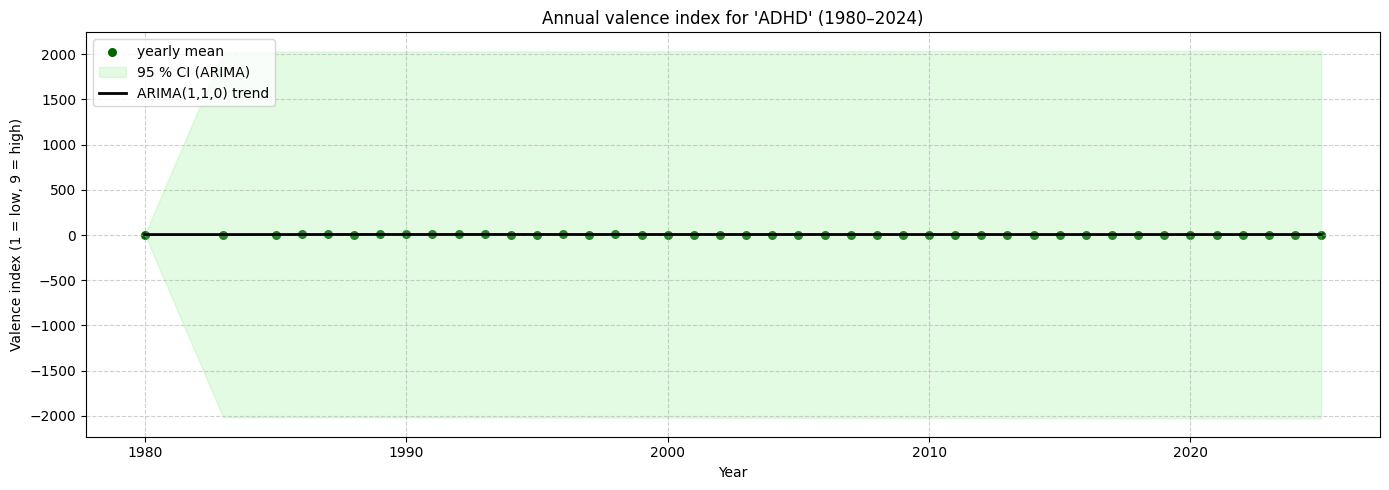

      lb_stat  lb_pvalue
6   15.177097   0.018923
12  23.900257   0.020986


In [30]:
%run 1_step4_fit_linear_model_valence-index.py

**Interpretation:** Fitting an ARIMA(1,1,0) + drift to the annual valence series (1980–2024) yields a near‐zero drift (Δvalence ≈ –0.006, p = .71) and a strongly negative AR(1) coefficient (φ₁ ≈ –0.52, p < .001), indicating that any deviation in a given year tends to “snap back” toward the long‐run mean rather than accumulate. Model selection criteria (AIC = –28.2; BIC = –31.5) favor this parsimonious specification, and diagnostic tests show no remaining autocorrelation (Ljung–Box p’s > .08), normal residuals (Jarque–Bera p = .42), or heteroskedasticity (White test p = .68). In substantive terms, the affective meaning of “ADHD” has been essentially flat over the past four decades, with only short‐lived, self‐correcting fluctuations around a stable baseline.

### VALIDATION checks: Valence contexts 

**Task 1:** Qualitatively inspect whether the valence scores match the sentences and go back to the original warriner_rat.csv to see if the lemmas that are being flagged as positive or negative make sense in the context of this corpus. If they don't, other options for rating dictionary files (apart from the Warriner Norms Data (2013)) are below (some may not require lemmatization):

    1. **NRC VAD Lexicon v2:** Norms for Valence, Arousal, and Dominance for over 55k English Terms
       - https://arxiv.org/abs/2503.23547
       - https://saifmohammad.com/WebPages/nrc-vad.html
    2. **Linguistic Inquiry and Word Count (Pennebaker et al., 2015):** - REQUIRES A *LICENSE*
    3. **Vader-lexicon (Hutto and Gilbert, 2014):** https://github.com/cjhutto/vaderSentiment
       -  VADER Sentiment Analysis. VADER (Valence Aware Dictionary and sEntiment Reasoner) is a lexicon and rule-based sentiment analysis tool that is specifically attuned to sentiments 
          expressed in social media, and works well on texts from other domains. 
    4. **DLATK (Schwartzet al., 2017):**
       - https://github.com/dlatk/dlatk
       - https://aclanthology.org/D17-2010/

**Task 2:** Check whether the lemmatization and segmentation model (en_core_web_sm) segmented and lemmatized the articles properly. If not, it can be upgraded.

**The Script:**:
1. **Loads valence ratings**: Import the Warriner et al. dictionary with valence scores for ~13k lemmas.
2. **Reads lemmatized files**: Open each TSV file with lemmatized sentences and metadata.
3. **Extracts context windows**: For each target word occurrence, grab 5 words before and after it.
4. **Computes valence**: Look up and average valence scores for all words in the context window.
5. **Normalizes and add metadata**: Scale valence to 0–1 and attach info (target, year, GOID, full text).
6. **Saves results**: Write all scored context windows to a single CSV.
7. **Extracts top/bottom examples**: For each decade, save the n highest and n lowest valence contexts to separate files for manual inspection.

In [2]:
#calculate descriptives for valence

import pandas as pd
import os

df_valence_descriptives = pd.read_csv('output/context_window_validation/all_context_window_valence_scores.csv')


# Calculate the mean of the 'scores' column
mean_score = df_valence_descriptives['avg_valence_index'].mean()

# Calculate the standard deviation of the 'scores' column
# By default, Pandas' .std() calculates the sample standard deviation (ddof=1)
#std_dev_score = df_valence_descriptives['avg_valence_index'].std()

# If you need the population standard deviation, set ddof=0
population_std_dev_score = df_valence_descriptives['avg_valence_index'].std(ddof=0)

print(f"Mean of scores: {mean_score}")
print(f"Standard deviation of scores: {population_std_dev_score}")



Mean of scores: 5.429706374971987
Standard deviation of scores: 0.881641484490275


## Annual Arousal Index
- **Measure**: Annual Count-Weighted Average Arousal over Co-occurrences of Target within 5-Word Context Window
- - Note: The steps below are equivalent to the explanations above, but replace the valence ratings from the Warriner norms data with arousal ratings.

In [12]:
#%run 1_step3_compute_arousal-index.py
%run 1_step3_compute_arousal-index_sentences.py

Sentence corpus shape: (103598, 13)
Sentence corpus columns: ['id', 'title', 'publisher', 'source_type', 'pub_province', 'year', 'raw_sent', 'full_article_text', 'sentence_len', 'sentence_word_len', 'article_len', 'article_word_len', 'lemmatized_sent']
Warriner columns: ['Unnamed: 0', 'word', 'V.Mean.Sum', 'V.SD.Sum', 'V.Rat.Sum', 'A.Mean.Sum', 'A.SD.Sum', 'A.Rat.Sum', 'D.Mean.Sum', 'D.SD.Sum', 'D.Rat.Sum', 'V.Mean.M', 'V.SD.M', 'V.Rat.M', 'V.Mean.F', 'V.SD.F', 'V.Rat.F', 'A.Mean.M', 'A.SD.M', 'A.Rat.M', 'A.Mean.F', 'A.SD.F', 'A.Rat.F', 'D.Mean.M', 'D.SD.M', 'D.Rat.M', 'D.Mean.F', 'D.SD.F', 'D.Rat.F', 'V.Mean.Y', 'V.SD.Y', 'V.Rat.Y', 'V.Mean.O', 'V.SD.O', 'V.Rat.O', 'A.Mean.Y', 'A.SD.Y', 'A.Rat.Y', 'A.Mean.O', 'A.SD.O', 'A.Rat.O', 'D.Mean.Y', 'D.SD.Y', 'D.Rat.Y', 'D.Mean.O', 'D.SD.O', 'D.Rat.O', 'V.Mean.L', 'V.SD.L', 'V.Rat.L', 'V.Mean.H', 'V.SD.H', 'V.Rat.H', 'A.Mean.L', 'A.SD.L', 'A.Rat.L', 'A.Mean.H', 'A.SD.H', 'A.Rat.H', 'D.Mean.L', 'D.SD.L', 'D.Rat.L', 'D.Mean.H', 'D.SD.H', 'D.Rat

### PLOT Arousal Indices

Merged shape: (36, 7)
   year  avg_arousal_index_window5  se_arousal_index_window5  \
0  1990                   4.090750                  0.030645   
1  1991                   4.100932                  0.036671   
2  1992                   4.037887                  0.036200   
3  1993                   4.107742                  0.030091   
4  1994                   4.117625                  0.027357   

   warriner_arousal_coverage_proportion_window5  avg_arousal_index_sentence  \
0                                      0.460183                    4.062146   
1                                      0.491972                    4.058861   
2                                      0.456107                    4.034997   
3                                      0.460967                    4.035409   
4                                      0.452381                    4.065788   

   se_arousal_index_sentence  warriner_arousal_coverage_proportion_sentence  
0                   0.019125            

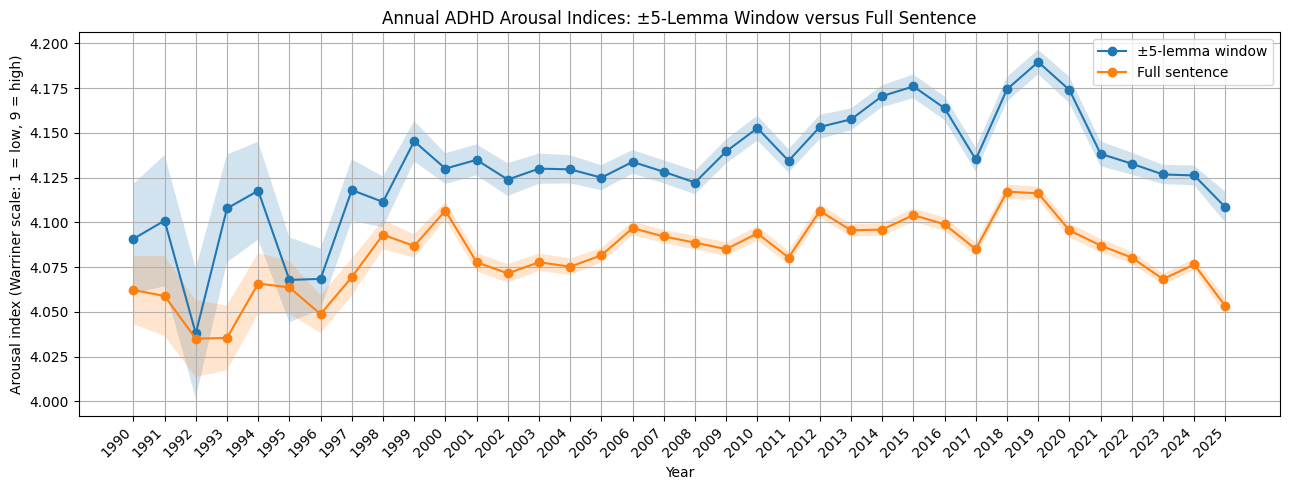

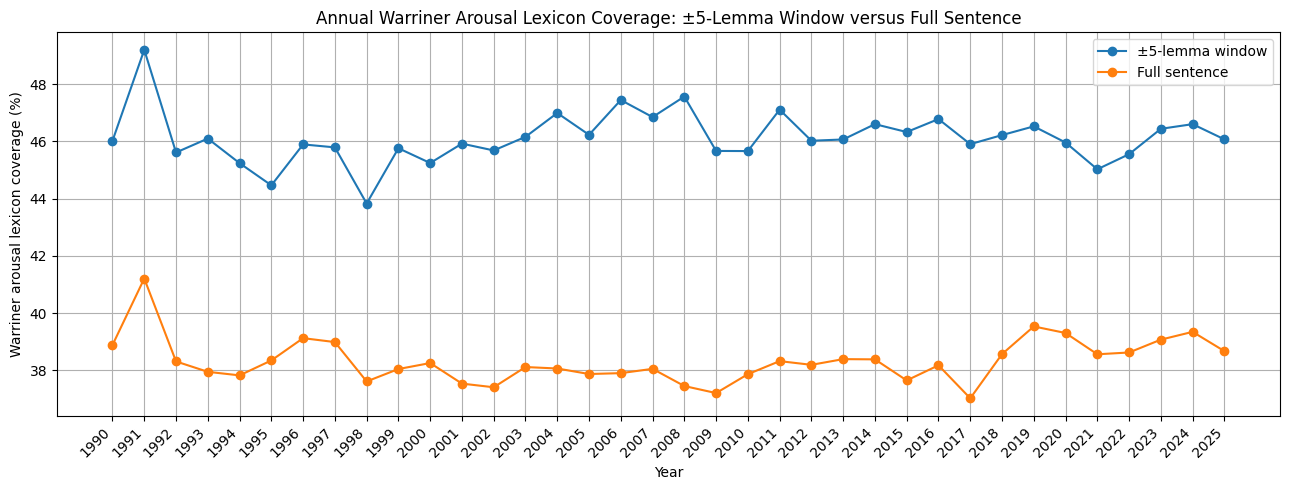

In [13]:
import pandas as pd
import matplotlib.pyplot as plt


# =========================================================
# Load and align both arousal specifications
# =========================================================

window_df = pd.read_csv(
    "output/annual_arousal_indices.csv"
)

sentence_df = pd.read_csv(
    "output/annual_arousal_indices_full_sentence.csv"
)

# Restrict to the study period
window_df = window_df[
    window_df["year"].between(1990, 2025)
].copy()

sentence_df = sentence_df[
    sentence_df["year"].between(1990, 2025)
].copy()

# Merge by year to ensure correct alignment
plot_df = window_df[
    [
        "year",
        "avg_arousal_index",
        "se_arousal_index",
        "warriner_arousal_coverage_proportion"
    ]
].merge(
    sentence_df[
        [
            "year",
            "avg_arousal_index",
            "se_arousal_index",
            "warriner_arousal_coverage_proportion"
        ]
    ],
    on="year",
    how="inner",
    suffixes=("_window5", "_sentence")
).sort_values("year")

print("Merged shape:", plot_df.shape)
print(plot_df.head())


# Convert to NumPy arrays for plotting
years = plot_df["year"].to_numpy()

arousal_window5 = (
    plot_df["avg_arousal_index_window5"].to_numpy()
)

se_window5 = (
    plot_df["se_arousal_index_window5"].to_numpy()
)

arousal_sentence = (
    plot_df["avg_arousal_index_sentence"].to_numpy()
)

se_sentence = (
    plot_df["se_arousal_index_sentence"].to_numpy()
)


# =========================================================
# Plot 1: Annual arousal indices
# =========================================================

plt.figure(figsize=(13, 5))

plt.plot(
    years,
    arousal_window5,
    marker="o",
    label="±5-lemma window"
)

plt.fill_between(
    years,
    arousal_window5 - se_window5,
    arousal_window5 + se_window5,
    alpha=0.20
)

plt.plot(
    years,
    arousal_sentence,
    marker="o",
    label="Full sentence"
)

plt.fill_between(
    years,
    arousal_sentence - se_sentence,
    arousal_sentence + se_sentence,
    alpha=0.20
)

plt.xticks(
    ticks=years,
    labels=years.astype(str),
    rotation=45,
    ha="right"
)

plt.xlabel("Year")
plt.ylabel(
    "Arousal index "
    "(Warriner scale: 1 = low, 9 = high)"
)
plt.title(
    "Annual ADHD Arousal Indices: "
    "±5-Lemma Window versus Full Sentence"
)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


# =========================================================
# Plot 2: Warriner arousal coverage
# =========================================================

coverage_window5 = (
    plot_df[
        "warriner_arousal_coverage_proportion_window5"
    ].to_numpy()
    * 100
)

coverage_sentence = (
    plot_df[
        "warriner_arousal_coverage_proportion_sentence"
    ].to_numpy()
    * 100
)

plt.figure(figsize=(13, 5))

plt.plot(
    years,
    coverage_window5,
    marker="o",
    label="±5-lemma window"
)

plt.plot(
    years,
    coverage_sentence,
    marker="o",
    label="Full sentence"
)

plt.xticks(
    ticks=years,
    labels=years.astype(str),
    rotation=45,
    ha="right"
)

plt.xlabel("Year")
plt.ylabel("Warriner arousal lexicon coverage (%)")
plt.title(
    "Annual Warriner Arousal Lexicon Coverage: "
    "±5-Lemma Window versus Full Sentence"
)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [20]:
import pandas as pd
import statsmodels.api as sm
from scipy.stats import pearsonr


# =========================================================
# Load outputs
# =========================================================

val_window = pd.read_csv(
    "output/annual_valence_indices.csv"
)

val_sentence = pd.read_csv(
    "output/annual_valence_indices_full_sentence.csv"
)

aro_window = pd.read_csv(
    "output/annual_arousal_indices.csv"
)

aro_sentence = pd.read_csv(
    "output/annual_arousal_indices_full_sentence.csv"
)

dataframes = [
    val_window,
    val_sentence,
    aro_window,
    aro_sentence
]

for df in dataframes:
    df.drop(
        df[~df["year"].between(1990, 2025)].index,
        inplace=True
    )
    df.sort_values("year", inplace=True)


# =========================================================
# Coverage summaries
# =========================================================

coverage_specs = [
    (
        "Valence ±5",
        val_window,
        "warriner_valence_coverage_proportion"
    ),
    (
        "Valence full sentence",
        val_sentence,
        "warriner_valence_coverage_proportion"
    ),
    (
        "Arousal ±5",
        aro_window,
        "warriner_arousal_coverage_proportion"
    ),
    (
        "Arousal full sentence",
        aro_sentence,
        "warriner_arousal_coverage_proportion"
    )
]

for name, df, column in coverage_specs:
    coverage_percent = df[column] * 100

    print(f"\n{name}")
    print(f"Mean: {coverage_percent.mean():.3f}%")
    print(f"SD:   {coverage_percent.std(ddof=1):.3f}%")
    print(f"Min:  {coverage_percent.min():.3f}%")
    print(f"Max:  {coverage_percent.max():.3f}%")

    # Test whether coverage changes linearly over time
    X = sm.add_constant(df["year"])
    model = sm.OLS(coverage_percent, X).fit()

    print(
        f"Annual slope: {model.params['year']:.4f} "
        f"percentage points/year"
    )
    print(f"Slope p-value: {model.pvalues['year']:.4f}")


# =========================================================
# Check whether valence and arousal coverage are identical
# =========================================================

print("\nCoverage equality checks:")

print(
    "±5 valence/arousal coverage identical:",
    val_window[
        "warriner_valence_coverage_proportion"
    ].reset_index(drop=True).equals(
        aro_window[
            "warriner_arousal_coverage_proportion"
        ].reset_index(drop=True)
    )
)

print(
    "Sentence valence/arousal coverage identical:",
    val_sentence[
        "warriner_valence_coverage_proportion"
    ].reset_index(drop=True).equals(
        aro_sentence[
            "warriner_arousal_coverage_proportion"
        ].reset_index(drop=True)
    )
)


# =========================================================
# Correlations between context specifications
# =========================================================

val_merged = val_window[
    ["year", "avg_valence_index"]
].merge(
    val_sentence[
        ["year", "avg_valence_index"]
    ],
    on="year",
    suffixes=("_window5", "_sentence")
)

aro_merged = aro_window[
    ["year", "avg_arousal_index"]
].merge(
    aro_sentence[
        ["year", "avg_arousal_index"]
    ],
    on="year",
    suffixes=("_window5", "_sentence")
)

val_r, val_p = pearsonr(
    val_merged["avg_valence_index_window5"],
    val_merged["avg_valence_index_sentence"]
)

aro_r, aro_p = pearsonr(
    aro_merged["avg_arousal_index_window5"],
    aro_merged["avg_arousal_index_sentence"]
)

print("\nIndex correlations:")
print(f"Valence: r = {val_r:.3f}, p = {val_p:.6g}")
print(f"Arousal: r = {aro_r:.3f}, p = {aro_p:.6g}")


Valence ±5
Mean: 46.124%
SD:   0.912%
Min:  43.829%
Max:  49.197%
Annual slope: 0.0076 percentage points/year
Slope p-value: 0.6105

Valence full sentence
Mean: 38.333%
SD:   0.783%
Min:  37.028%
Max:  41.210%
Annual slope: 0.0029 percentage points/year
Slope p-value: 0.8238

Arousal ±5
Mean: 46.124%
SD:   0.912%
Min:  43.829%
Max:  49.197%
Annual slope: 0.0076 percentage points/year
Slope p-value: 0.6105

Arousal full sentence
Mean: 38.333%
SD:   0.783%
Min:  37.028%
Max:  41.210%
Annual slope: 0.0029 percentage points/year
Slope p-value: 0.8238

Coverage equality checks:
±5 valence/arousal coverage identical: True
Sentence valence/arousal coverage identical: True

Index correlations:
Valence: r = 0.910, p = 1.45868e-14
Arousal: r = 0.839, p = 1.68706e-10


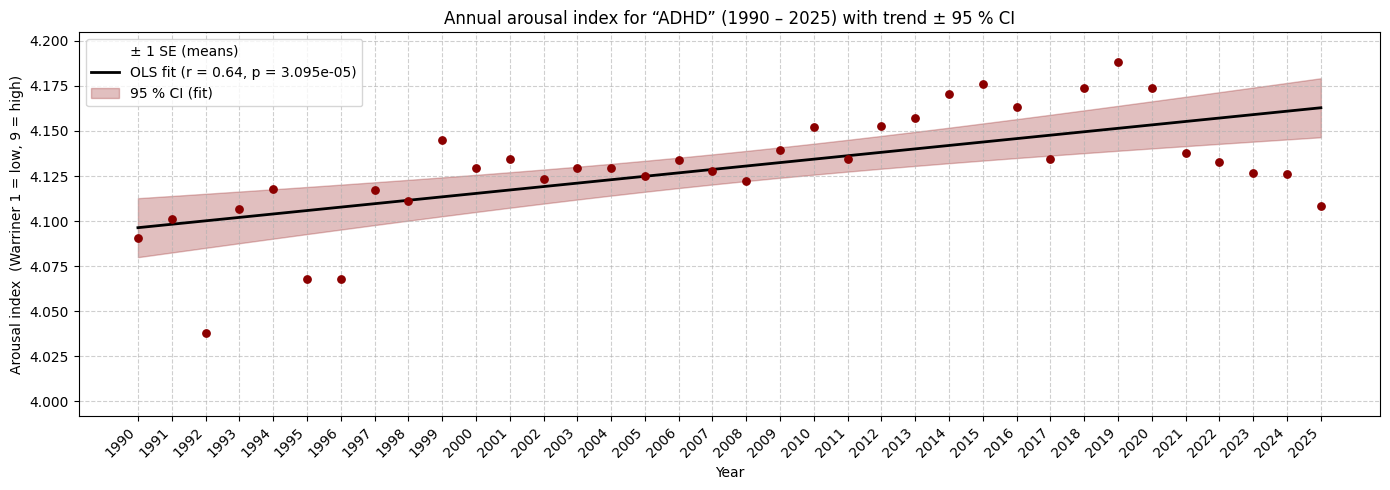

── — OLS summary ─────────────────────
n (years)        : 36
Slope            : +0.0019   (± 0.0004)
Intercept        : +0.3131
R-squared        : 0.4042
Pearson r        : 0.6357
p-value (slope)  : 3.095e-05
────────────────────────────────────────────────────



In [35]:
%run 1_step4_fit_OLS_arousal-index.py # HOWEVER, RESIDUALS IN TIME SERIES ARE OFTEN AUTOCORRELATED (SO OLS MAY NOT BE APPROPRIATE!)

### STATS: Linear Regression Model - Fitting the Outcome Variable as a Function of Year

Time series analysis for psychological research: examining and forecasting change: https://doi.org/10.3389/fpsyg.2015.00727

Durbin–Watson = 1.043
Using GLS-AR(1); ρ = 0.44


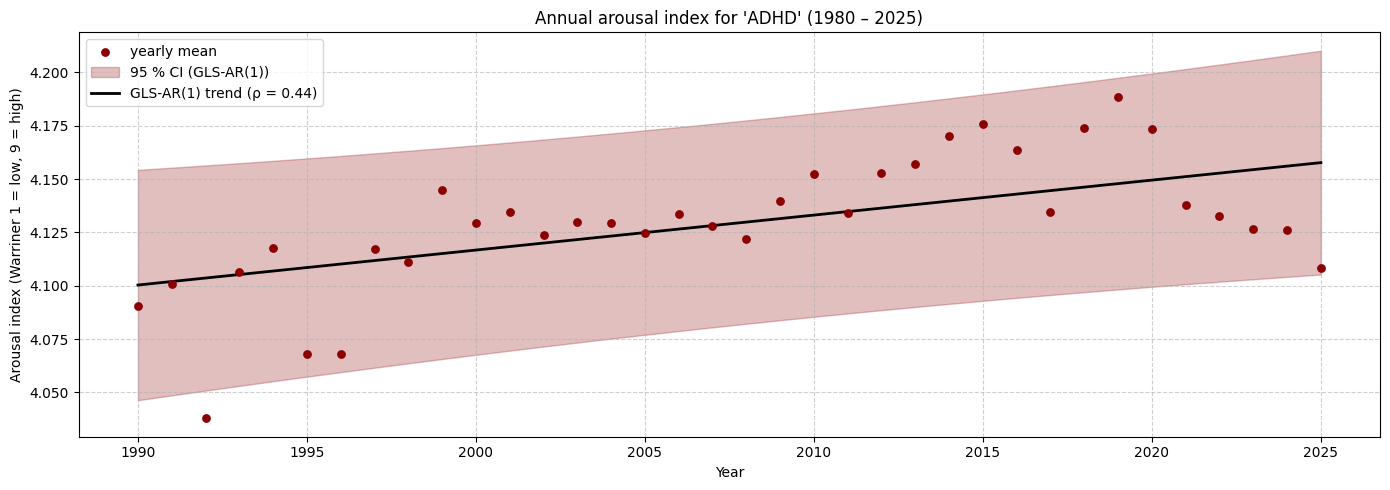

                           GLSAR Regression Results                           
Dep. Variable:                      y   R-squared:                       0.155
Model:                          GLSAR   Adj. R-squared:                  0.130
Method:                 Least Squares   F-statistic:                     6.067
Date:                Mon, 22 Sep 2025   Prob (F-statistic):             0.0192
Time:                        09:04:42   Log-Likelihood:                 84.240
No. Observations:                  35   AIC:                            -164.5
Df Residuals:                      33   BIC:                            -161.4
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.8396      1.336      0.628      0.5

In [36]:
%run 1_step4_fit_linear_model_arousal-index.py # try a simple GLS fit this time as a first step

**Method**:  For each target word we extracted annual mean arousal scores from 1980 – 2024 (45 observations) and modelled change over time with a linear trend. We first fitted an ordinary–least–squares (OLS) regression of yearly arousal on calendar year. Residual serial correlation was assessed with the Durbin–Watson (DW) statistic. When DW lay between 1.5 and 2.5 we retained the OLS solution because the residuals showed little autocorrelation; otherwise we refitted the data with a generalised least-squares model that assumes first-order autoregressive errors, GLS-AR(1), and estimated the AR parameter (ρ) iteratively. Point-wise 95 % confidence bands for the fitted line were obtained from the model’s predicted standard errors (Newey–West–HAC for OLS, GLS covariance for AR(1) fits). Trend lines and confidence ribbons were plotted for visual inspection.

**Summary**:  The initial OLS fit yielded DW = 0.63, indicating substantial positive autocorrelation, so the model was refitted with GLS-AR(1). The estimated autoregressive coefficient was ρ = 0.69, confirming strong year-to-year persistence. After allowing for this correlation the linear slope was positive but small and non-significant (β = 0.0027 ± 0.0017, p = 0.12; 95 % CI = -0.001 … 0.006). The trend accounted for only 5.6 % of the variance (R² = 0.06). Residual diagnostics (DW = 1.81; Omnibus and Jarque–Bera p > 0.20) showed no material departures from independence or normality once the AR(1) structure was imposed. In sum, the affective tone of “schizophrenia” has remained essentially stable over the past four decades, with any upward drift too small to reach statistical significance after adjusting for serial correlation.

## Which words contribute most to valence and arousal indices/ Sentiment and Intensity trends?

Step 1) Compute significant beta coefficients and CI
Step 2) compute top contributing lemmas for the significant time periods

In [3]:
#!pip install statsmodels

In [5]:
!python 1_step3_compute_valence+arousal-index_significant_slopes.py

Valence data: 1990–2025 (36 years)
Arousal data: 1990–2025 (36 years)

VALENCE / SENTIMENT
Quadratic model: R² = 0.844; adjusted R² = 0.835
Linear term: b = -0.010261, p = 2.084e-14
Quadratic term: b = 0.00030998, p = 0.001011
Estimated turning point: 2024.05

SIGNIFICANT DIRECTION OF FITTED TREND
  Decreasing : 1990–2017
  No clear slope: 2018–2025
  Increasing : None

AROUSAL / INTENSITY
Quadratic model: R² = 0.587; adjusted R² = 0.562
Linear term: b = 0.001903, p = 2.519e-06
Quadratic term: b = -0.00013853, p = 0.0005376
Estimated turning point: 2014.37

SIGNIFICANT DIRECTION OF FITTED TREND
  Decreasing : 2023–2025
  No clear slope: 2012–2022
  Increasing : 1990–2011

TREND-PHASE TRANSITIONS

Valence / Sentiment
  1990: Significant decrease | slope = -0.02111, 95% CI [-0.02744, -0.01478], p = 9.803e-08
  2018: No significant change | slope = -0.00375, 95% CI [-0.00777, 0.00026], p = 0.06604

Arousal / Intensity
  1990: Significant increase | slope = 0.00675, 95% CI [0.00409, 0.0094

In [14]:
!python 1_step3_compute_valence+arousal-index_top-words-SPLIT.py \
    --input-root output/cooccurrences_by_year \
    --target ADHD \
    --ratings-file ../resources/warriner_rat.csv \
    --output-root output/valence_arousal_contributions \
    --flat-output \
    --start-year 1990 \
    --end-year 2025

Processing ADHD: 100%|█████████████████████████| 36/36 [00:03<00:00, 10.40it/s]

CONTRIBUTOR SUMMARY: ADHD

VALENCE — declining_valence (1990-2017)
  Aggregate fitted change: -0.340036
  Aggregate linear slope: -0.012594 (p=4.29e-11)
  Sum of word contributions: -0.340036
  Decomposition check gap: -1.776e-15
  Top 5 same-direction contributors: translator, ordinary, surgeon, metabolism, adjoining
  Top 5 account for 0.00% of same-direction contribution
  Top directional contributors:
    child              contribution=-0.115468 | Δfreq_hat=-0.054059 | rating=7.20 | share=15.01%
    autism             contribution=-0.033663 | Δfreq_hat=+0.018059 | rating=3.20 | share=4.38%
    anxiety            contribution=-0.025191 | Δfreq_hat=+0.009385 | rating=2.38 | share=3.28%
    parent             contribution=-0.022020 | Δfreq_hat=-0.013218 | rating=6.73 | share=2.86%
    depression         contribution=-0.020583 | Δfreq_hat=+0.007844 | rating=2.44 | share=2.68%
    add                contri

In [16]:
# Note: This script relies on you running "1_step3_compute_valence+arousal-index_top-words.py" above

!python 1_step3_summarise_valence_arousal_contributions.py \
    --target ADHD \
    --output-root output/valence_arousal_contributions \
    --flat-output \
    --top-n 10 \
    --opposing-n 5



PHASE CONTRIBUTION SUMMARY: ADHD

VALENCE — declining_valence (1990–2017)
---------------------------------------
Aggregate fitted change: -0.340036; slope/year = -0.012594, p < .001
Decomposition: word contributions sum to -0.340036; gap = -1.776e-15
Top 5 account for 0.00% and top 10 for 0.00% of same-direction contribution.
Top 10 contributors to the decrease:
   1. child              contribution=-0.115468 | share=15.01% | Δfreq_hat=-0.054059 | rating=7.20
   2. autism             contribution=-0.033663 | share= 4.38% | Δfreq_hat=+0.018059 | rating=3.20
   3. anxiety            contribution=-0.025191 | share= 3.28% | Δfreq_hat=+0.009385 | rating=2.38
   4. parent             contribution=-0.022020 | share= 2.86% | Δfreq_hat=-0.013218 | rating=6.73
   5. depression         contribution=-0.020583 | share= 2.68% | Δfreq_hat=+0.007844 | rating=2.44
   6. add                contribution=-0.015136 | share= 1.97% | Δfreq_hat=-0.012982 | rating=6.23
   7. attention          contribution=-

### VALIDATION checks: Valence contexts 

In [10]:
!python 1_step5_validation_checks_high-low-valence-contexts.py \
  --input-file output/ADHD_US_newsstream_normalized-ADHD_sentences_cleaned_lemmatized.csv \
  --ratings-file ../resources/warriner_rat.csv \
  --output-root output \
  --window 5 \
  --top-n 50 \
  --target adhd


--- Valence Validation Config ---
    input_file: output/ADHD_US_newsstream_normalized-ADHD_sentences_cleaned_lemmatized.csv
  ratings_file: ../resources/warriner_rat.csv
   output_root: output
        target: adhd
        window: 5
         top_n: 50
   flat_output: False
           sep: ,
--------------------------------

Processing sentences: 100%|████████████| 103598/103598 [07:21<00:00, 234.50it/s]
✓ Saved all windows ➜ output/context_window_validation/adhd/all_context_window_valence_scores.csv
✓ Saved top/bottom 50 ➜ output/context_window_validation/adhd/global_top50_valence_windows.csv / output/context_window_validation/adhd/global_bottom50_valence_windows.csv
✓ Saved coverage (global) ➜ output/context_window_validation/adhd/coverage_global_valence.csv
✓ Saved coverage (by year) ➜ output/context_window_validation/adhd/coverage_by_year_valence.csv
✓ Saved coverage (by decade) ➜ output/context_window_validation/adhd/coverage_by_decade_valence.csv


In [13]:
import os
import glob
import pandas as pd

# ------------ configure here ------------
base_dir = "output/context_window_validation"
target   = "adhd"        # e.g. "schizophrenia" or "schizophrenic"
metric   = "valence"              # "valence" or "arousal"
top_n    = 50                     # matches the script's --top-n
# ---------------------------------------

# pretty display
pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

# paths & filenames
out_dir   = os.path.join(base_dir, target)
top_name  = f"global_top{top_n}_{metric}_windows.csv"
bot_name  = f"global_bottom{top_n}_{metric}_windows.csv"
top_path  = os.path.join(out_dir, top_name)
bot_path  = os.path.join(out_dir, bot_name)

def ensure_file(path, pattern):
    if os.path.exists(path):
        return path
    # helpful diagnostics
    print(f"[WARN] Could not find: {os.path.basename(path)} in {os.path.dirname(path)}")
    print("       Available files:")
    for f in sorted(glob.glob(os.path.join(os.path.dirname(path), "*.csv"))):
        print("       -", os.path.basename(f))
    # try best-effort glob on pattern
    candidates = sorted(glob.glob(os.path.join(os.path.dirname(path), pattern)))
    if candidates:
        print(f"[INFO] Using closest match: {os.path.basename(candidates[-1])}")
        return candidates[-1]
    raise FileNotFoundError(path)

# allow flexible matching if filenames differ slightly
top_path = ensure_file(top_path, f"global_top*_{metric}_windows.csv")
bot_path = ensure_file(bot_path, f"global_bottom*_{metric}_windows.csv")

# read
top_df = pd.read_csv(top_path)
bot_df = pd.read_csv(bot_path)

# columns to show
common_cols = ["GOID", "year", "context_window", "lemmatized_sentence", "raw_sentence",
               "Publisher", "SourceType", "PublisherProvince", "Title"]
metric_cols = (["avg_valence_index", "se_valence_index"] 
               if metric == "valence" 
               else ["avg_arousal_index", "se_arousal_index"])

cols = [c for c in metric_cols + common_cols if c in top_df.columns]

print(f"\n✅ Loaded {metric} windows for target='{target}'")
print("Top file:", os.path.basename(top_path))
print("Bottom file:", os.path.basename(bot_path))

print("\n🔺 Top 10 high-{} contexts:\n".format(metric))
display(top_df[cols].head(10))

print("\n🔻 Bottom 10 low-{} contexts:\n".format(metric))
display(bot_df[cols].head(10))


✅ Loaded valence windows for target='adhd'
Top file: global_top50_valence_windows.csv
Bottom file: global_bottom50_valence_windows.csv

🔺 Top 10 high-valence contexts:



,avg_valence_index,se_valence_index,year,context_window,lemmatized_sentence
0,8.470,0.000,2012,"serena also has , so mounts is happy","serena also has adhd , so mounts is happy to know there will be additional therapy available at brockbank ."
1,8.150,0.100,2014,carol gignoux of live free . 7 p.m. free,carol gignoux of live adhd free . 7 p.m. free .
2,8.125,0.345,2006,"kiss , happy endings , , tripstar 8 p.m. tomorrow","st . louis movie star kiss , happy endings , adhd , tripstar 8 p.m. tomorrow at mississippi nights , 914 n. first st. ; $ 6 ."
3,8.110,0.000,2019,he has and he was excited about,"he has adhd and he was excited about ( the change ) . """
4,8.100,0.150,2020,live free,live adhd free
5,8.100,0.150,2020,"about carol gignoux and live free : carol gignoux ,","about carol gignoux and live adhd free : carol gignoux , m. ed . , author of “ your innovator brain : the truth about adhd , ” is one of the foremost thought leader on the subject of adhd and other innovator brain type ."
6,8.000,0.000,2024,with or love someone with .,the award - win content creator share the ultimate survival guide to live with or love someone with adhd .
7,8.000,0.000,2010,"prize , and she has herself .","she 's a journalist who win a pulitzer prize , and she has adhd herself ."
8,7.975,0.025,2014,someone you love live with ?,free discussion is someone you love live with adhd ?
9,7.950,0.000,2016,", "" live well with . ""","afterstrive to well understand the challenge people face with the disorder , huff decide to compile his finding and experience into his new book , "" live well with adhd . """



🔻 Bottom 10 low-valence contexts:



,avg_valence_index,se_valence_index,year,context_window,lemmatized_sentence
0,1.40,0.0,2014,over and over again is torture .,doing the same thing over and over again is adhd torture .
1,1.53,0.0,2000,"been abuse , he 's .",""" what we historically have done is look at a packet and say , ' geez , he 's a bedwetter , he 's been abuse , he 's adhd ."
2,1.53,0.0,2025,“ she has ; she was abuse by,"“ she has adhd ; she was abuse by my dad , ” griffith say ."
3,1.53,0.0,2009,""" david is , and he was abuse",""" david is adhd , and he was abuse , "" davis say ."
4,1.68,0.0,2010,", whether in cds , or alzheimer 's disease .","under the amend term of the agreement , astrazeneca has an option for an exclusive license to tc-5619 for various cognitive disorder the first time that tc-5619 achieve clinical proof of concept , whether in cds , adhd or alzheimer 's disease ."
5,1.68,0.0,2001,"either parkinson 's disease or , and altropane is the","there are presently no objective test for either parkinson 's disease or adhd , and altropane is the only such test for both disorder in commercial development in the u.s."
6,1.68,0.0,2001,") , which is that is not a disease ,","the column was a criticism of john rosemond 's viewpoint ( also david stein 's viewpoint ) , which is that adhd is not a disease , and that medication such as ritalin can cause serious harm ."
7,1.68,0.0,2000,"of parkinson 's disease and ; troponin i , a","blsi 's product in development include : altropane , a radioimaging agent for the diagnosis of parkinson 's disease and adhd ; troponin i , a naturally - occur anti- angiogenesis factor for the treatment of solid tumor ; af-1 and inosine , nerve growth factor for the treatment of acute and chronic cns disorder ; fusion toxin for the treatment of cancer and multiple sclerosis ; novel therapy for the treatment of parkinson 's disease and adhd ; and transcription factor that may control the expression of molecule associate with autoimmune disease and allergy ."
8,1.68,0.0,2024,"as alzheimer 's disease or , it is often not",""" in disorder such as alzheimer 's disease or adhd , it is often not memory storage , but rather the ability to focus on and retain a memory once it is form that is the problem , "" say rutishauser , who is a professor of neurosurgery , neurology and biomedical sciences at cedars - sinai ."
9,1.68,0.0,2005,", parkinson 's disease and .","three month ago , when his condition worsen , they switch him to a cocktail of drug that is normally used to treat depression , parkinson 's disease and adhd ."


### VALIDATION checks: Arousal contexts 

In [14]:
!python 1_step5_validation_checks_high-low-arousal-contexts.py \
  --input-file output/ADHD_US_newsstream_normalized-ADHD_sentences_cleaned_lemmatized.csv \
  --ratings-file ../resources/warriner_rat.csv \
  --output-root output \
  --window 5 \
  --top-n 50 \
  --target adhd


--- Arousal Validation Config ---
    input_file: output/ADHD_US_newsstream_normalized-ADHD_sentences_cleaned_lemmatized.csv
  ratings_file: ../resources/warriner_rat.csv
   output_root: output
        target: adhd
        window: 5
         top_n: 50
   flat_output: False
           sep: ,
--------------------------------

Processing sentences: 100%|████████████| 103598/103598 [08:02<00:00, 214.57it/s]
✓ Saved all windows ➜ output/context_window_validation/adhd/all_context_window_arousal_scores.csv
✓ Saved top/bottom 50 ➜ output/context_window_validation/adhd/global_top50_arousal_windows.csv / output/context_window_validation/adhd/global_bottom50_arousal_windows.csv
✓ Saved coverage (global) ➜ output/context_window_validation/adhd/coverage_global_arousal.csv
✓ Saved coverage (by year) ➜ output/context_window_validation/adhd/coverage_by_year_arousal.csv
✓ Saved coverage (by decade) ➜ output/context_window_validation/adhd/coverage_by_decade_arousal.csv


In [1]:
#calculate descriptives for arousal

import pandas as pd
import os

df_arousal_descriptives = pd.read_csv('output/context_window_validation/all_context_window_arousal_scores.csv')


# Calculate the mean of the 'scores' column
mean_score_arousal = df_arousal_descriptives['avg_arousal_index'].mean()

# Calculate the standard deviation of the 'scores' column
# By default, Pandas' .std() calculates the sample standard deviation (ddof=1)
#std_dev_score = df_varousal_descriptives['avg_arousal_index'].std()

# If you need the population standard deviation, set ddof=0
population_std_dev_score_arousal = df_arousal_descriptives['avg_arousal_index'].std(ddof=0)

print(f"Mean of scores: {mean_score_arousal}")
print(f"Standard deviation of scores: {population_std_dev_score_arousal}")

Mean of scores: 4.143422712564778
Standard deviation of scores: 0.5136062259765192


In [15]:
import os
import glob
import pandas as pd

# ------------ configure here ------------
base_dir = "output/context_window_validation"
target   = "adhd"        # target
metric   = "arousal"              # "valence" or "arousal"
top_n    = 50                     # matches the script's --top-n
# ---------------------------------------

# pretty display
pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

# paths & filenames
out_dir   = os.path.join(base_dir, target)
top_name  = f"global_top{top_n}_{metric}_windows.csv"
bot_name  = f"global_bottom{top_n}_{metric}_windows.csv"
top_path  = os.path.join(out_dir, top_name)
bot_path  = os.path.join(out_dir, bot_name)

def ensure_file(path, pattern):
    if os.path.exists(path):
        return path
    # helpful diagnostics
    print(f"[WARN] Could not find: {os.path.basename(path)} in {os.path.dirname(path)}")
    print("       Available files:")
    for f in sorted(glob.glob(os.path.join(os.path.dirname(path), "*.csv"))):
        print("       -", os.path.basename(f))
    # try best-effort glob on pattern
    candidates = sorted(glob.glob(os.path.join(os.path.dirname(path), pattern)))
    if candidates:
        print(f"[INFO] Using closest match: {os.path.basename(candidates[-1])}")
        return candidates[-1]
    raise FileNotFoundError(path)

# allow flexible matching if filenames differ slightly
top_path = ensure_file(top_path, f"global_top*_{metric}_windows.csv")
bot_path = ensure_file(bot_path, f"global_bottom*_{metric}_windows.csv")

# read
top_df = pd.read_csv(top_path)
bot_df = pd.read_csv(bot_path)

# columns to show
common_cols = ["GOID", "year", "context_window", "lemmatized_sentence", "raw_sentence",
               "Publisher", "SourceType", "PublisherProvince", "Title"]
metric_cols = (["avg_valence_index", "se_valence_index"] 
               if metric == "valence" 
               else ["avg_arousal_index", "se_arousal_index"])

cols = [c for c in metric_cols + common_cols if c in top_df.columns]

print(f"\n✅ Loaded {metric} windows for target='{target}'")
print("Top file:", os.path.basename(top_path))
print("Bottom file:", os.path.basename(bot_path))

print("\n🔺 Top 10 high-{} contexts:\n".format(metric))
display(top_df[cols].head(10))

print("\n🔻 Bottom 10 low-{} contexts:\n".format(metric))
display(bot_df[cols].head(10))


✅ Loaded arousal windows for target='adhd'
Top file: global_top50_arousal_windows.csv
Bottom file: global_bottom50_arousal_windows.csv

🔺 Top 10 high-arousal contexts:



,avg_arousal_index,se_arousal_index,year,context_window,lemmatized_sentence
0,7.60,0.0,2002,5 to 18 ) with and 139 age- and sex,"dr. xavier castellanos , now a radiologist at new york university school of medicine , giedd and a dozen other nimh colleague follow 152 child and adolescent ( age 5 to 18 ) with adhd and 139 age- and sex - match control , bring them into the laboratory every two year ."
1,7.60,0.0,2005,"about sex , bullying and .","topic for future forum include talk to teen about sex , bullying and adhd ."
2,7.05,0.0,2007,attack and adderall for the .,"grow up , she take seroquel for the anxiety attack and adderall for the adhd ."
3,6.95,0.0,2000,"( r)-ddms for , ( s)-ddms for sexual","( r)-ddms for adhd , ( s)-ddms for sexual dysfunction , and ( s)-doxazosin for benign prostatic hyperplasia are currently in phase i."
4,6.86,0.0,2023,"with money issues , an .","by sara murphy perspectivesfor women with money issues , an adhd ."
5,6.86,0.0,2023,"with money issues , an .","for woman with money issues , an adhd ."
6,6.81,0.0,2024,"kill by and ocd "" and ""","kill by adhd and ocd "" and "" here is pinky . 1998 ."
7,6.80,0.0,2004,up to speed on ( ) .,and you just ca n't expect every primary care physician to keep up to speed on ( adhd ) .
8,6.76,0.0,2012,", such as schizophrenia and . """,""" computerized training to perform cognitive task , like those used in our study , has show promise in cognitive rehabilitation , and for treatment of mental illness and condition , such as schizophrenia and adhd . """
9,6.76,0.0,2020,"schizophrenia , ptsd . and .","accord to the lawsuit , settles suffer from bipolar disorder , schizophrenia , ptsd . and adhd ."



🔻 Bottom 10 low-arousal contexts:



,avg_arousal_index,se_arousal_index,year,context_window,lemmatized_sentence
0,1.67,0.0,2018,are calm for those with .,"weighted blanket are also show to benefit people with sensory processing disorder like autism , and are calm for those with adhd ."
1,1.67,0.0,2018,"calm , especially with my . """,""" it help me keep calm , especially with my adhd . """
2,1.67,0.0,2014,"in those with , it calm down hyperactivity","in those with adhd , it calm down hyperactivity ."
3,1.67,0.0,1998,"he has , but he is calm","he has adhd , but he is calm and more focused with medication ."
4,1.95,0.0,2007,"he has , is quiet and has","he has adhd , is quiet and has difficulty open up to others ."
5,2.15,0.0,2014,"it is title "" : is it all about","it is title "" adhd : is it all about attention or is there more to it ? """
6,2.15,0.0,2013,the level of impairment their has on themselves .,"some individual may choose to stop medication and will rely on the "" trick "" they have learn to minimize the level of impairment their adhd has on themselves ."
7,2.15,0.0,2013,"level , "" he has ; if not , he","so determine whether a kid has been properly diagnose should be straightforward : if he has "" abnormal chemical level , "" he has adhd ; if not , he does n't ."
8,2.15,0.0,2013,same level as someone without .,"in a very basic explanation of how adhd medication help those who need it , reff explain that for a person diagnose with adhd , part of their brain , which is responsible for focus , plan and pay attention is not function at the same level as someone without adhd ."
9,2.15,0.0,2022,segmentationapplication narcolepsy othersgeography north america europe,segmentationapplication adhd narcolepsy othersgeography north america europe asia rest of world ( row)central nervous system ( cns ) stimulant drugs market 2022 - 2026 :


## VALIDATION - Warriner coverage

In [16]:
import os
import pandas as pd

OUTPUT_ROOT = "output/context_window_validation"
TARGETS = ["adhd"]
METRICS = ["valence", "arousal"]   # do both in one go

def load_by_year_exact(target: str, metric: str) -> pd.DataFrame | None:
    fname = f"coverage_by_year_{metric}.csv"
    p1 = os.path.join(OUTPUT_ROOT, target, fname)
    p2 = os.path.join(OUTPUT_ROOT, f"{target}_{fname}")
    path = p1 if os.path.exists(p1) else (p2 if os.path.exists(p2) else None)
    if not path:
        print(f"[WARN] Missing coverage-by-year for {metric} / {target}")
        return None

    df = pd.read_csv(path)
    # ensure we have percent_matched
    if "percent_matched" not in df.columns and \
       {"matched_tokens", "total_ctx_tokens"}.issubset(df.columns):
        m = df["matched_tokens"].astype(float)
        n = df["total_ctx_tokens"].astype(float)
        df["percent_matched"] = (m / n.where(n > 0, pd.NA)) * 100.0

    return df[["year", "percent_matched"]]

stats_rows = []

for metric in METRICS:
    for tgt in TARGETS:
        df = load_by_year_exact(tgt, metric)
        if df is None or df.empty:
            continue

        pm = pd.to_numeric(df["percent_matched"], errors="coerce").dropna()

        stats_rows.append({
            "target": tgt,
            "metric": metric,
            "n_years": len(pm),
            "mean_percent_matched": pm.mean(),          # M
            "sd_percent_matched": pm.std(ddof=1),       # SD (sample)
            "min_percent_matched": pm.min(),
            "max_percent_matched": pm.max(),
        })

stats = pd.DataFrame(stats_rows)
display(stats)

# write out for the paper / record
out_path = os.path.join(OUTPUT_ROOT, "coverage_by_year_summary_stats.csv")
stats.to_csv(out_path, index=False)
print("Saved summary stats to:", out_path)


,target,metric,n_years,mean_percent_matched,sd_percent_matched,min_percent_matched,max_percent_matched
0,adhd,valence,39,37.965253,1.143122,36.363636,42.682927
1,adhd,arousal,39,37.965253,1.143122,36.363636,42.682927


Saved summary stats to: output/context_window_validation/coverage_by_year_summary_stats.csv


## coverage plot - warriner vs nrc-vad

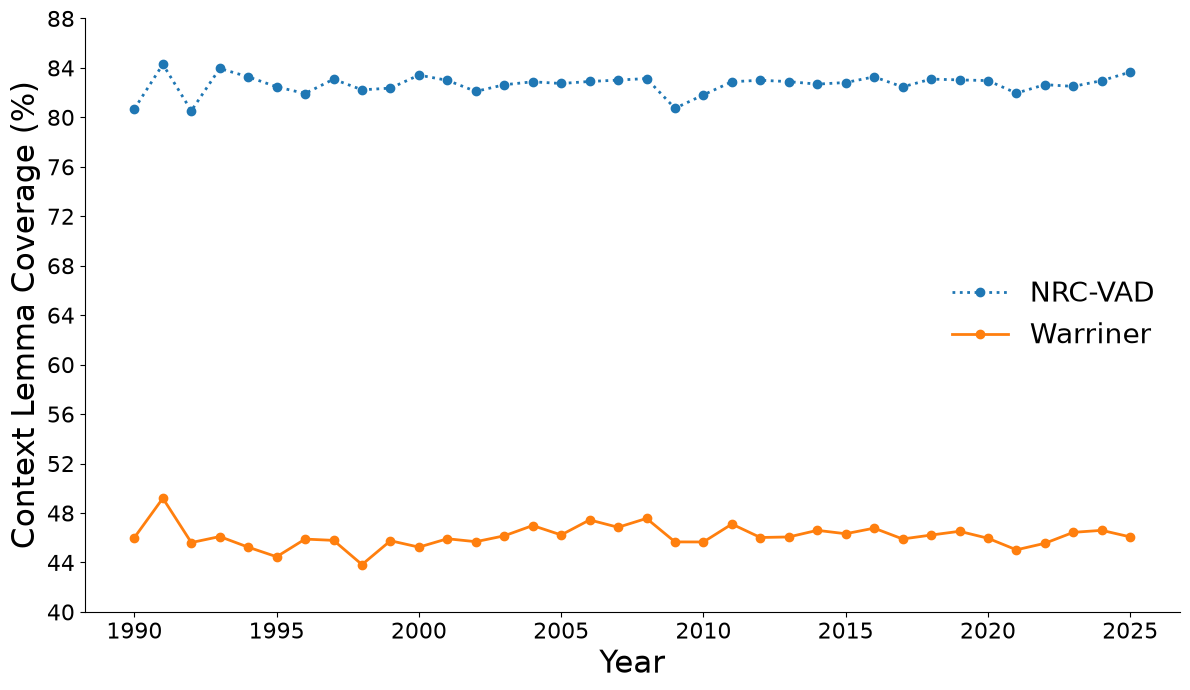

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# Load files
warriner = pd.read_csv("output/annual_arousal_indices.csv")
nrc = pd.read_csv("output/annual_arousal_indices_nrc.csv")

# Keep only the years available in both files
df = warriner[[
    "year",
    "warriner_arousal_coverage_proportion"
]].merge(
    nrc[[
        "year",
        "nrc_arousal_coverage_proportion"
    ]],
    on="year"
)

# Convert proportions to percentages
df["Warriner"] = df["warriner_arousal_coverage_proportion"] * 100
df["NRC-VAD"] = df["nrc_arousal_coverage_proportion"] * 100

# Plot
fig, ax = plt.subplots(figsize=(12, 7))

ax.plot(
    df["year"],
    df["NRC-VAD"],
    marker="o",
    linestyle=":",
    linewidth=2,
    markersize=6,
    label="NRC-VAD"
)

ax.plot(
    df["year"],
    df["Warriner"],
    marker="o",
    linestyle="-",
    linewidth=2,
    markersize=6,
    label="Warriner"
)

ax.set_xlabel("Year", fontsize=22)
ax.set_ylabel("Context Lemma Coverage (%)", fontsize=22)

ax.tick_params(axis="both", labelsize=16)

ax.set_ylim(40, 88)
ax.set_yticks(range(40, 89, 4))

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(
    frameon=False,
    fontsize=20,
    loc="center right"
)

plt.tight_layout()

plt.savefig(
    "output/Figure_S1_Warriner_NRC_coverage.svg",
    format="svg",
    bbox_inches="tight"
)

plt.savefig(
    "output/Figure_S1_Warriner_NRC_coverage.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

# End of Script